In [29]:
#Importamos librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

## Analisis Exploratorio Tabla de Coyuntura

La tabla de coyuntura es una base de datos con información recopilada por Camacol acerca de los principales indicadores del sector construcción. Esta compuesta por 5 tablas de contingencia que abarcan los siguientes temas:

- **Lanzamientos:** Contempla la apertura de nuevas unidades de vivienda a través de proyectos que empiezan a ofrecerse para su comercialización (preventa)
- **Iniciaciones:** Corresponde a las unidades de vivienda que iniciaron proceso de construcción.
- **Ventas:** Corresponde a unidades terminadas que son comercializadas en el mercado.
- **Oferta:** Hace referencia a unidades disponibles para la venta.
- 
Cada tabla contiene información (en unidades de vivienda) desglosada por rangos de precio según el salario mínimo mensual legal para cada periodo, donde cada registro reporta la información para cada regional de manera mensual con datos desde el 2006 .

A continuación, se presenta la relación de las regionales que se abordan en la tabla de coyuntura, los municipios que la componen y el periodo desde que se posee información.

| Inicio Recolección | Regional | Municipios |
|---:|---|---|
| 2006 | Bogotá & Cundinamarca | Anapoima, Apulo, Bogotá, D.C., Cajicá, Chía, Cota, Facatativá, Funza, Fusagasugá, Gachancipá, Girardot, La Calera, La Mesa, La Vega, Madrid, Mosquera, Ricaurte, Sibaté, Soacha, Sopó, Tabio, Tenjo, Tocancipá, Villeta, Zipaquirá. |
| 2006 | Tolima | Ibagué. |
| 2007 | Bolívar | Arjona, Cartagena de Indias, Magangué, Turbaco. |
| 2007 | Caldas | Aguadas, Anserma, Chinchiná, La Dorada, Manizales, Neira, Palestina, Villamaría. |
| 2008 | Risaralda | Dosquebradas, Pereira, Santa Rosa de Cabal. |
| 2008 | Antioquia | Amagá, Andes, Apartadó, Barbosa, Bello, Caldas, Carepa, Chigorodó, Copacabana, El Carmen de Viboral, El Santuario, Envigado, Girardota, Guarne, Guatapé, Itagüí, Jardín, La Ceja, La Estrella, La Unión, Marinilla, Medellín, Peñol, Retiro, Rionegro, Sabaneta, San Jerónimo, San Juan de Urabá, Santa Fé de Antioquia, Sopetrán, Támesis, Turbo. |
| 2008 | Boyacá | Duitama, Paipa, Sogamoso, Tunja. |
| 2008 | Nariño | Pasto. |
| 2008 | Santander | Barrancabermeja, Bucaramanga, Floridablanca, Girón, Piedecuesta, San Gil. |
| 2008 | Valle | Buenaventura, Cali, Calima, Candelaria, Cartago, El Cerrito, Florida, Ginebra, Guadalajara de Buga, Jamundí, Palmira, Roldanillo, Tuluá, Yumbo. |
| 2009 | Huila | Garzón, La Plata, Neiva, Pitalito. |
| 2009 | Norte de Santander | Chinácota, Cúcuta, Los Patios, Villa del Rosario. |
| 2010 | Atlántico | Barranquilla, Galapa, Malambo, Puerto Colombia, Sabanalarga, Soledad, Tubará. |
| 2014 | Cesar | Valledupar. |
| 2014 | Meta | Acacías, Barranca de Upía, Puerto López, Restrepo, San Martín, Villavicencio. |
| 2015 | Córdoba & Sucre | Montería, Sincelejo. |
| 2015 | Magdalena | Santa Marta. |
| 2017 | Quindío | Armenia. |
| 2019 | Cauca | Popayán, Puerto Tejada, Santander de Quilichao. |

De esta manera, Camacol brinda información de la cantidad de viviendas referente a las perspectivas de Lanzamientos, Inicializaciones, Ventas y Oferta para cada mes del año, agrupando las viviendas por zona regional y por el tipo de vivienda (en relación con el valor en SMMLV). 

<div align="center">
    <img src="Composicion_Region.png" width="70%">
</div>


Importamos cada una de las hojas del archivo de excel en un dataframe

In [81]:
df_l = pd.read_excel('Bases/Tablas de Coyuntura_sep26.xlsx',sheet_name='Lanzamientos')
df_i = pd.read_excel('Bases/Tablas de Coyuntura_sep26.xlsx',sheet_name='Iniciaciones')
df_v = pd.read_excel('Bases/Tablas de Coyuntura_sep26.xlsx',sheet_name='Ventas')
df_o = pd.read_excel('Bases/Tablas de Coyuntura_sep26.xlsx',sheet_name='Oferta')

In [82]:
df_l.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Columns: 162 entries, Unidades de vivienda to Unnamed: 161
dtypes: object(162)
memory usage: 271.0+ KB


In [176]:
df_l.head(10)

,Unidades de vivienda,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161
0,Fuente: Coordenada Urbana,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fecha,Antioquia,NaN,NaN,NaN,NaN,NaN,NaN,Atlántico,NaN,...,NaN,NaN,NaN,19 Regionales,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),...,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL
5,2010-01-01 00:00:00,0,162,580,95,162,675,837,0,54,...,2903,3837,6740,247,2656,2997,840,2903,3837,6740
6,2010-02-01 00:00:00,0,643,1141,262,643,1403,2046,0,6,...,5843,4204,10047,1047,4796,3401,803,5843,4204,10047
7,2010-03-01 00:00:00,6,628,729,144,634,873,1507,0,222,...,5733,4171,9904,232,5501,3530,641,5733,4171,9904
8,2010-04-01 00:00:00,0,1240,313,130,1240,443,1683,0,0,...,4880,2693,7573,912,3968,2112,581,4880,2693,7573
9,2010-05-01 00:00:00,0,647,764,121,647,885,1532,0,0,...,4487,3424,7911,46,4441,2639,785,4487,3424,7911


Importada la información, procederemos a analizar cada hoja en una sección individual.

### Lanzamientos

In [83]:
# Fila que contiene las regionales
regionales = df_l.iloc[3].ffill()
# Fila que contiene las categorías de vivienda
categorias = df_l.iloc[4]
# Construir nombres de columnas
columnas = ['Fecha']

for i in range(1, df_l.shape[1]):
    regional = str(regionales.iloc[i]).strip()
    categoria = str(categorias.iloc[i]).strip()

    columnas.append(f'{regional}__{categoria}')

In [84]:
df_lanzamientos = df_l.iloc[5:-8].copy()
df_lanzamientos.columns = columnas
df_lanzamientos.reset_index(drop=True, inplace=True)
df_lanzamientos=df_lanzamientos.set_index("Fecha")

C:\Users\57302\anaconda3\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [85]:
df_lanzamientos.index = pd.to_datetime(df_lanzamientos.index)
df_lanzamientos.index.name = "Fecha"

In [86]:
df_lanzamientos.columns

Index(['Antioquia__VIP', 'Antioquia__VIS (sin VIP)',
       'Antioquia__> VIS y hasta 500 smml', 'Antioquia__Mayor a 500 smml',
       'Antioquia__VIS', 'Antioquia__NO VIS', 'Antioquia__TOTAL',
       'Atlántico__VIP', 'Atlántico__VIS (sin VIP)',
       'Atlántico__> VIS y hasta 500 smml',
       ...
       '18 Regionales__VIS', '18 Regionales__NO VIS', '18 Regionales__TOTAL',
       '19 Regionales__VIP', '19 Regionales__VIS (sin VIP)',
       '19 Regionales__> VIS y hasta 500 smml',
       '19 Regionales__Mayor a 500 smml', '19 Regionales__VIS',
       '19 Regionales__NO VIS', '19 Regionales__TOTAL'],
      dtype='object', length=161)

In [87]:
columnas_agrupadas = ["5 Regionales","13 Regionales","18 Regionales","19 Regionales"]

df_lanzamientos = df_lanzamientos.loc[
    :,
    [
        col for col in df_lanzamientos.columns
        if (
            col == "Fecha"
            or (
                col.strip().endswith("__TOTAL")
                and not any(
                    col.startswith(regional + "__")
                    for regional in columnas_agrupadas
                )
            )
        )
    ]
].copy()

In [88]:
df_lanzamientos = df_lanzamientos.loc[df_lanzamientos.index >= "2018-01-01"].copy()

In [89]:
df_lanzamientos.shape

(105, 19)

In [90]:
df_lanzamientos.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 105 entries, 2018-01-01 to 2026-09-01
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Antioquia__TOTAL              105 non-null    object
 1   Atlántico__TOTAL              105 non-null    object
 2   Bogotá & Cundinamarca__TOTAL  105 non-null    object
 3   Bolívar__TOTAL                105 non-null    object
 4   Boyacá__TOTAL                 105 non-null    object
 5   Caldas__TOTAL                 105 non-null    object
 6   Huila__TOTAL                  105 non-null    object
 7   Nariño__TOTAL                 105 non-null    object
 8   Norte de Santander__TOTAL     105 non-null    object
 9   Risaralda__TOTAL              105 non-null    object
 10  Santander__TOTAL              105 non-null    object
 11  Tolima__TOTAL                 105 non-null    object
 12  Valle__TOTAL                  105 non-null    object
 13  C

In [91]:
df_lanzamientos = df_lanzamientos.astype('Int64')

In [92]:
df_lanzamientos.head(5)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2018-01-01,1022,440,3310,1714,225,689,0,518,1001,673,177,138,1103,160,80,150,0,180,1
2018-02-01,2782,153,8169,1117,231,190,22,51,342,440,667,565,1199,111,80,295,225,96,568
2018-03-01,4057,1494,3262,997,275,368,0,208,28,507,78,792,2603,187,208,83,182,49,104
2018-04-01,664,1554,3743,715,195,194,125,11,510,252,190,164,2171,264,52,0,356,400,536
2018-05-01,2068,1409,5478,279,202,304,295,0,259,1994,1003,164,424,89,312,290,373,135,11


In [93]:
df_lanzamientos.tail(10)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2025-12-01,823,1320,3718,910,267,457,240,14,292,180,198,344,1491,256,138,40,0,12,120
2026-01-01,506,1196,2883,576,189,0,60,6,85,0,460,236,488,24,14,40,907,120,152
2026-02-01,2748,911,5472,468,200,220,58,20,264,260,58,188,1307,44,335,55,248,116,88
2026-03-01,2007,1294,5626,177,210,228,0,0,194,522,329,252,1997,27,0,77,1349,527,133
2026-04-01,527,796,3568,396,183,140,54,0,182,525,0,172,1372,131,0,102,549,106,0
2026-05-01,1997,524,4443,871,24,137,484,90,78,332,304,368,227,352,125,107,400,49,0
2026-06-01,1135,579,3246,1329,201,309,80,102,233,522,152,369,409,55,0,100,195,21,0
2026-07-01,2293,320,4392,160,62,0,40,38,68,599,288,192,319,17,0,43,80,181,152
2026-08-01,848,372,4063,464,66,198,0,0,0,360,130,300,526,210,88,127,0,0,52


In [94]:
df_lanz_stats=df_lanzamientos.describe().T
df_lanz_stats.style.format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max
Antioquia__TOTAL,105.00,"1,809.90","1,161.12",258.00,"1,022.00","1,537.00","2,183.00","7,002.00"
Atlántico__TOTAL,105.00,"1,249.54",861.06,48.00,648.00,"1,052.00","1,567.00","4,691.00"
Bogotá & Cundinamarca__TOTAL,105.00,"5,256.30","2,078.08","2,131.00","3,718.00","4,980.00","6,245.00","13,999.00"
Bolívar__TOTAL,105.00,703.06,383.27,0.00,430.00,674.00,910.00,"1,799.00"
Boyacá__TOTAL,105.00,171.39,100.23,0.00,102.00,154.00,231.00,436.00
Caldas__TOTAL,105.00,222.24,181.96,0.00,84.00,183.00,334.00,973.00
Huila__TOTAL,105.00,179.21,192.72,0.00,22.00,128.00,240.00,820.00
Nariño__TOTAL,105.00,76.70,123.97,0.00,0.00,24.00,118.00,732.00
Norte de Santander__TOTAL,105.00,266.96,233.47,0.00,80.00,220.00,359.00,"1,105.00"
Risaralda__TOTAL,105.00,400.79,292.09,0.00,199.00,357.00,537.00,"1,994.00"


In [95]:
df_lanzamientos.isna().sum()

Antioquia__TOTAL                0
Atlántico__TOTAL                0
Bogotá & Cundinamarca__TOTAL    0
Bolívar__TOTAL                  0
Boyacá__TOTAL                   0
Caldas__TOTAL                   0
Huila__TOTAL                    0
Nariño__TOTAL                   0
Norte de Santander__TOTAL       0
Risaralda__TOTAL                0
Santander__TOTAL                0
Tolima__TOTAL                   0
Valle__TOTAL                    0
Cesar__TOTAL                    0
Meta__TOTAL                     0
Córdoba & Sucre__TOTAL          0
Magdalena__TOTAL                0
Quindío__TOTAL                  0
Cauca__TOTAL                    0
dtype: int64

In [96]:
df_lanzamientos.index.duplicated().sum()

np.int64(0)

In [97]:
fechas_esperadas = pd.date_range(
    start=df_lanzamientos.index.min(),
    end=df_lanzamientos.index.max(),
    freq='MS'
)

fechas_faltantes = fechas_esperadas.difference(df_lanzamientos.index)

print(fechas_faltantes)

DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


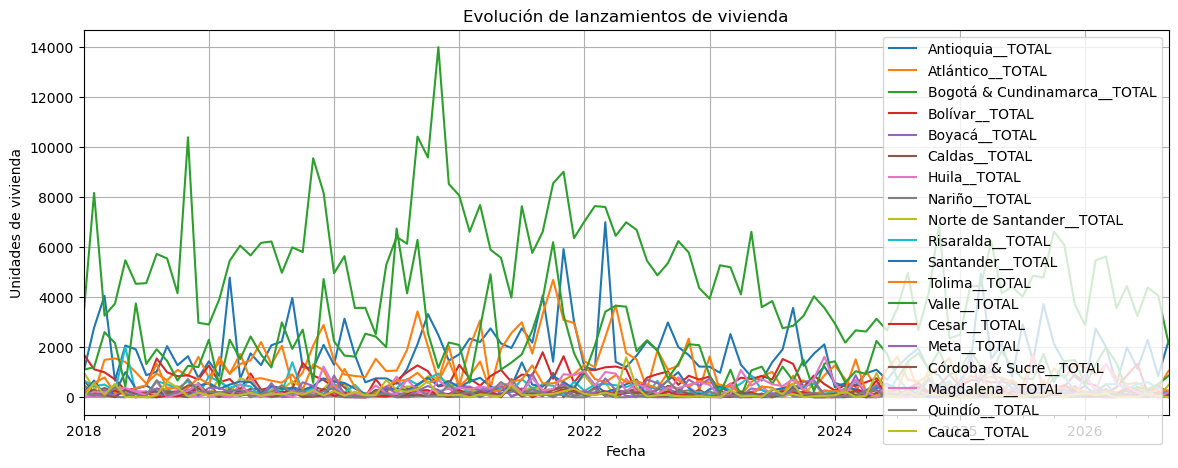

In [98]:
df_lanzamientos.plot(
    figsize=(14, 5),
    title='Evolución de lanzamientos de vivienda',
    xlabel='Fecha',
    ylabel='Unidades de vivienda',
    grid=True
)

plt.show()

### Iniciaciones

In [99]:
df_i.head(10)

,Unidades de vivienda,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161
0,Fuente: Coordenada Urbana,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fecha,Antioquia,NaN,NaN,NaN,NaN,NaN,NaN,Atlántico,NaN,...,NaN,NaN,NaN,19 Regionales,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),...,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL
5,2010-01-01 00:00:00,0,214,567,135,214,702,916,0,54,...,3537,4196,7733,219,3318,3433,763,3537,4196,7733
6,2010-02-01 00:00:00,20,391,282,80,411,362,773,0,312,...,3249,4279,7528,48,3201,3572,707,3249,4279,7528
7,2010-03-01 00:00:00,0,120,423,0,120,423,543,0,510,...,4161,4281,8442,490,3671,3785,496,4161,4281,8442
8,2010-04-01 00:00:00,0,1050,564,130,1050,694,1744,0,24,...,6414,3677,10091,8,6406,2827,850,6414,3677,10091
9,2010-05-01 00:00:00,0,418,530,30,418,560,978,0,37,...,3956,3083,7039,6,3950,2236,847,3956,3083,7039


In [100]:
df_i.tail(10)

,Unidades de vivienda,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161
204,2026-08-01 00:00:00,0,668,456,0,668,456,1124,0,0,...,5579,2489,8068,312,5267,2044,445,5579,2489,8068
205,2026-09-01 00:00:00,0,396,387,93,396,480,876,180,640,...,3496,3523,7019,350,3146,3150,373,3496,3523,7019
206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
207,oct 24 - sep 25,252,6933,6292,2736,7185,9028,16213,981,3456,...,79569,38321,117890,13956,67391,30369,7983,81347,38352,119699
208,oct 25 - sep 26,64,7973,6619,1866,8037,8485,16522,1194,2537,...,72687,39702,112389,9143,63914,32873,7028,73057,39901,112958
209,var anual%,-0.746032,0.150007,0.051971,-0.317982,0.11858,-0.060146,0.019059,0.217125,-0.265914,...,-0.086491,0.036038,-0.046662,-0.34487,-0.051594,0.082453,-0.119629,-0.101909,0.040389,-0.056316
210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,Año corrido sep25,252,5933,4953,1664,6185,6617,12802,981,2476,...,60549,27830,88379,11119,50560,22742,5119,61679,27861,89540
212,Año corrido sep26,64,5986,4653,842,6050,5495,11545,280,1961,...,51516,27663,79179,5372,46357,23537,4267,51729,27804,79533
213,var anual%,-0.746032,0.008933,-0.060569,-0.49399,-0.021827,-0.169563,-0.098188,-0.714577,-0.207997,...,-0.149185,-0.006001,-0.104097,-0.516863,-0.083129,0.034957,-0.166439,-0.161319,-0.002046,-0.11176


In [101]:
# Fila que contiene las regionales
regionales_ini = df_i.iloc[3].ffill()
# Fila que contiene las categorías de vivienda
categorias_ini = df_i.iloc[4]
# Construir nombres de columnas
columnas_ini = ['Fecha']

for i in range(1, df_i.shape[1]):
    regional_ini = str(regionales_ini.iloc[i]).strip()
    categoria_ini = str(categorias_ini.iloc[i]).strip()

    columnas_ini.append(f'{regional_ini}__{categoria_ini}')

In [102]:
df_iniciaciones = df_i.iloc[5:-8].copy()
df_iniciaciones.columns = columnas_ini
df_iniciaciones.reset_index(drop=True, inplace=True)
df_iniciaciones=df_iniciaciones.set_index("Fecha")

C:\Users\57302\anaconda3\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [103]:
df_iniciaciones.index = pd.to_datetime(df_iniciaciones.index)
df_iniciaciones.index.name = "Fecha"

In [104]:
df_iniciaciones.columns

Index(['Antioquia__VIP', 'Antioquia__VIS (sin VIP)',
       'Antioquia__> VIS y hasta 500 smml', 'Antioquia__Mayor a 500 smml',
       'Antioquia__VIS', 'Antioquia__NO VIS', 'Antioquia__TOTAL',
       'Atlántico__VIP', 'Atlántico__VIS (sin VIP)',
       'Atlántico__> VIS y hasta 500 smml',
       ...
       '18 Regionales__VIS', '18 Regionales__NO VIS', '18 Regionales__TOTAL',
       '19 Regionales__VIP', '19 Regionales__VIS (sin VIP)',
       '19 Regionales__> VIS y hasta 500 smml',
       '19 Regionales__Mayor a 500 smml', '19 Regionales__VIS',
       '19 Regionales__NO VIS', '19 Regionales__TOTAL'],
      dtype='object', length=161)

In [105]:
df_iniciaciones = df_iniciaciones.loc[
    :,
    [
        col for col in df_iniciaciones.columns
        if (
            col == "Fecha"
            or (
                col.strip().endswith("__TOTAL")
                and not any(
                    col.startswith(regional + "__")
                    for regional in columnas_agrupadas
                )
            )
        )
    ]
].copy()

In [106]:
df_iniciaciones = df_iniciaciones.loc[df_iniciaciones.index >= "2018-01-01"].copy()

In [107]:
df_iniciaciones.shape

(105, 19)

In [108]:
df_iniciaciones.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 105 entries, 2018-01-01 to 2026-09-01
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Antioquia__TOTAL              105 non-null    object
 1   Atlántico__TOTAL              105 non-null    object
 2   Bogotá & Cundinamarca__TOTAL  105 non-null    object
 3   Bolívar__TOTAL                105 non-null    object
 4   Boyacá__TOTAL                 105 non-null    object
 5   Caldas__TOTAL                 105 non-null    object
 6   Huila__TOTAL                  105 non-null    object
 7   Nariño__TOTAL                 105 non-null    object
 8   Norte de Santander__TOTAL     105 non-null    object
 9   Risaralda__TOTAL              105 non-null    object
 10  Santander__TOTAL              105 non-null    object
 11  Tolima__TOTAL                 105 non-null    object
 12  Valle__TOTAL                  105 non-null    object
 13  C

In [110]:
df_iniciaciones = df_iniciaciones.astype('Int64')

In [111]:
df_iniciaciones.head(5)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2018-01-01,2644,2070,3201,130,104,339,0,784,811,2185,217,314,1118,56,692,418,52,182,40
2018-02-01,1807,1013,4000,1065,134,208,400,378,374,254,291,212,1924,36,0,108,238,137,137
2018-03-01,1524,1012,4609,342,163,598,41,51,52,493,192,521,1880,76,143,111,164,38,106
2018-04-01,1645,454,3514,362,55,151,96,75,348,240,344,818,495,0,206,96,35,0,80
2018-05-01,759,165,4232,48,128,84,12,132,196,100,319,174,627,96,60,0,211,576,168


In [112]:
df_iniciaciones.tail(10)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2025-12-01,791,96,4062,622,321,180,0,0,160,176,0,0,592,105,114,48,128,105,54
2026-01-01,1428,61,3391,806,151,85,376,0,82,96,152,434,180,0,120,0,390,243,0
2026-02-01,778,684,5251,444,204,159,128,6,270,100,160,1041,0,0,98,213,228,288,0
2026-03-01,1511,184,3370,973,337,281,60,34,116,0,551,822,1620,63,0,219,553,118,38
2026-04-01,1327,204,3433,396,302,36,0,0,78,224,28,414,428,142,236,180,338,0,208
2026-05-01,1829,44,5048,0,26,64,161,0,152,517,312,248,1036,190,168,36,786,36,0
2026-06-01,745,0,2424,388,210,251,300,0,36,614,96,0,845,210,128,16,0,26,88
2026-07-01,1927,1521,3043,375,314,20,0,102,66,91,114,352,1037,419,460,0,504,180,20
2026-08-01,1124,0,4353,1045,140,433,24,38,0,0,264,216,0,113,0,126,192,0,0


In [113]:
df_ini_stats=df_iniciaciones.describe().T
df_ini_stats.style.format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max
Antioquia__TOTAL,105.00,"1,567.01",760.66,405.00,"1,005.00","1,477.00","1,978.00","4,299.00"
Atlántico__TOTAL,105.00,975.43,768.08,0.00,420.00,879.00,"1,371.00","3,625.00"
Bogotá & Cundinamarca__TOTAL,105.00,"4,811.70","1,688.00",308.00,"3,574.00","4,535.00","5,818.00","10,264.00"
Bolívar__TOTAL,105.00,543.81,394.65,0.00,231.00,491.00,811.00,"2,063.00"
Boyacá__TOTAL,105.00,159.95,107.76,0.00,80.00,145.00,226.00,624.00
Caldas__TOTAL,105.00,168.02,147.28,0.00,64.00,129.00,233.00,846.00
Huila__TOTAL,105.00,142.60,145.26,0.00,22.00,95.00,240.00,556.00
Nariño__TOTAL,105.00,84.33,140.00,0.00,0.00,26.00,106.00,784.00
Norte de Santander__TOTAL,105.00,216.92,199.13,0.00,72.00,152.00,305.00,862.00
Risaralda__TOTAL,105.00,356.33,301.72,0.00,132.00,316.00,496.00,"2,185.00"


In [114]:
df_iniciaciones.isna().sum()

Antioquia__TOTAL                0
Atlántico__TOTAL                0
Bogotá & Cundinamarca__TOTAL    0
Bolívar__TOTAL                  0
Boyacá__TOTAL                   0
Caldas__TOTAL                   0
Huila__TOTAL                    0
Nariño__TOTAL                   0
Norte de Santander__TOTAL       0
Risaralda__TOTAL                0
Santander__TOTAL                0
Tolima__TOTAL                   0
Valle__TOTAL                    0
Cesar__TOTAL                    0
Meta__TOTAL                     0
Córdoba & Sucre__TOTAL          0
Magdalena__TOTAL                0
Quindío__TOTAL                  0
Cauca__TOTAL                    0
dtype: int64

In [115]:
df_iniciaciones.index.duplicated().sum()

np.int64(0)

In [116]:
fechas_esperadas = pd.date_range(
    start=df_iniciaciones.index.min(),
    end=df_iniciaciones.index.max(),
    freq='MS'
)

fechas_faltantes = fechas_esperadas.difference(df_iniciaciones.index)

print(fechas_faltantes)

DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


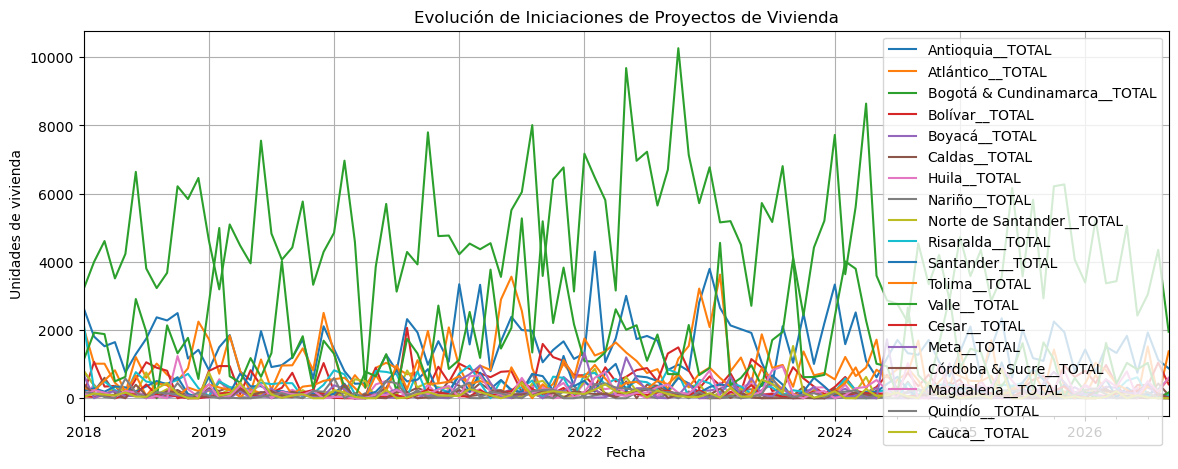

In [117]:
df_iniciaciones.plot(
    figsize=(14, 5),
    title='Evolución de Iniciaciones de Proyectos de Vivienda',
    xlabel='Fecha',
    ylabel='Unidades de vivienda',
    grid=True
)

plt.show()

### Ventas

In [118]:
df_v.head(10)

,Unidades de vivienda,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161
0,Fuente: Coordenada Urbana,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fecha,Antioquia,NaN,NaN,NaN,NaN,NaN,NaN,Atlántico,NaN,...,NaN,NaN,NaN,19 Regionales,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),...,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL
5,2010-01-01 00:00:00,2,434,568,111,436,679,1115,0,117,...,4282,4476,8758,339,3943,3456,1020,4282,4476,8758
6,2010-02-01 00:00:00,0,723,724,154,723,878,1601,1,373,...,4974,4777,9751,479,4495,3761,1016,4974,4777,9751
7,2010-03-01 00:00:00,7,711,711,141,718,852,1570,0,201,...,5534,4687,10221,285,5249,3685,1002,5534,4687,10221
8,2010-04-01 00:00:00,2,1201,494,144,1203,638,1841,1,65,...,5110,3649,8759,252,4858,2689,960,5110,3649,8759
9,2010-05-01 00:00:00,1,580,518,128,581,646,1227,0,155,...,5079,3692,8771,246,4833,2727,965,5079,3692,8771


In [119]:
df_v.tail(10)

,Unidades de vivienda,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161
204,2026-08-01 00:00:00,49,714,644,84,763,728,1491,202,578,...,8987,3751,12738,1497,7574,3309,453,9071,3762,12833
205,2026-09-01 00:00:00,40,683,624,124,723,748,1471,143,630,...,8313,3413,11726,1264,7124,2897,531,8388,3428,11816
206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
207,oct 24 - sep 25,166,9935,9037,3988,10101,13025,23126,3473,8659,...,115965,56260,172225,18295,99299,44084,12443,117594,56527,174121
208,oct 25 - sep 26,402,8404,9004,2443,8806,11447,20253,2354,7909,...,111857,50985,162842,16152,96949,42410,8745,113101,51155,164256
209,var anual%,1.421687,-0.154102,-0.003652,-0.387412,-0.128205,-0.121152,-0.124232,-0.3222,-0.086615,...,-0.035424,-0.093761,-0.054481,-0.117136,-0.023666,-0.037973,-0.297195,-0.038208,-0.095034,-0.056656
210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,Año corrido sep25,148,8136,7224,3060,8284,10284,18568,2488,6750,...,89541,43998,133539,13339,77374,34609,9558,90713,44167,134880
212,Año corrido sep26,345,6131,6671,1277,6476,7948,14424,1877,5714,...,81827,36001,117828,12625,70090,31041,5088,82715,36129,118844
213,var anual%,1.331081,-0.246436,-0.07655,-0.58268,-0.218252,-0.227149,-0.22318,-0.245579,-0.153481,...,-0.08615,-0.181758,-0.117651,-0.053527,-0.09414,-0.103095,-0.467671,-0.088168,-0.181991,-0.118891


In [120]:
# Fila que contiene las regionales
regionales_ven = df_v.iloc[3].ffill()
# Fila que contiene las categorías de vivienda
categorias_ven = df_v.iloc[4]
# Construir nombres de columnas
columnas_ven = ['Fecha']

for i in range(1, df_v.shape[1]):
    regional_ven = str(regionales_ven.iloc[i]).strip()
    categoria_ven = str(categorias_ven.iloc[i]).strip()

    columnas_ven.append(f'{regional_ven}__{categoria_ven}')

In [121]:
df_ventas = df_v.iloc[5:-8].copy()
df_ventas.columns = columnas_ven
df_ventas.reset_index(drop=True, inplace=True)
df_ventas=df_ventas.set_index("Fecha")

C:\Users\57302\anaconda3\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [122]:
df_ventas.index = pd.to_datetime(df_ventas.index)
df_ventas.index.name = "Fecha"

In [123]:
df_ventas.columns

Index(['Antioquia__VIP', 'Antioquia__VIS (sin VIP)',
       'Antioquia__> VIS y hasta 500 smml', 'Antioquia__Mayor a 500 smml',
       'Antioquia__VIS', 'Antioquia__NO VIS', 'Antioquia__TOTAL',
       'Atlántico__VIP', 'Atlántico__VIS (sin VIP)',
       'Atlántico__> VIS y hasta 500 smml',
       ...
       '18 Regionales__VIS', '18 Regionales__NO VIS', '18 Regionales__TOTAL',
       '19 Regionales__VIP', '19 Regionales__VIS (sin VIP)',
       '19 Regionales__> VIS y hasta 500 smml',
       '19 Regionales__Mayor a 500 smml', '19 Regionales__VIS',
       '19 Regionales__NO VIS', '19 Regionales__TOTAL'],
      dtype='object', length=161)

In [124]:
df_ventas = df_ventas.loc[
    :,
    [
        col for col in df_ventas.columns
        if (
            col == "Fecha"
            or (
                col.strip().endswith("__TOTAL")
                and not any(
                    col.startswith(regional + "__")
                    for regional in columnas_agrupadas
                )
            )
        )
    ]
].copy()

In [125]:
df_ventas = df_ventas.loc[df_ventas.index >= "2018-01-01"].copy()

In [126]:
df_ventas.shape

(105, 19)

In [127]:
df_ventas.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 105 entries, 2018-01-01 to 2026-09-01
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Antioquia__TOTAL              105 non-null    object
 1   Atlántico__TOTAL              105 non-null    object
 2   Bogotá & Cundinamarca__TOTAL  105 non-null    object
 3   Bolívar__TOTAL                105 non-null    object
 4   Boyacá__TOTAL                 105 non-null    object
 5   Caldas__TOTAL                 105 non-null    object
 6   Huila__TOTAL                  105 non-null    object
 7   Nariño__TOTAL                 105 non-null    object
 8   Norte de Santander__TOTAL     105 non-null    object
 9   Risaralda__TOTAL              105 non-null    object
 10  Santander__TOTAL              105 non-null    object
 11  Tolima__TOTAL                 105 non-null    object
 12  Valle__TOTAL                  105 non-null    object
 13  C

In [128]:
df_ventas = df_ventas.astype('Int64')

In [129]:
df_ventas.head(5)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2018-01-01,1703,1114,4489,927,175,344,182,209,576,566,439,497,1385,238,306,203,476,368,66
2018-02-01,2102,1009,6537,690,178,250,459,206,468,525,407,374,1604,143,230,184,223,327,142
2018-03-01,2256,899,5688,845,195,346,124,198,314,444,353,475,1451,153,222,161,196,274,187
2018-04-01,1715,985,5267,838,208,250,169,182,449,437,443,423,2090,296,250,105,293,262,134
2018-05-01,1729,936,5564,765,192,211,189,184,402,598,489,405,1725,120,225,281,203,193,127


In [130]:
df_ventas.tail(10)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2025-12-01,1677,1334,5554,826,240,285,170,47,234,340,425,505,1191,195,287,112,484,256,106
2026-01-01,1548,1182,5270,894,234,177,220,29,172,221,440,541,1240,87,266,81,492,249,125
2026-02-01,1691,1099,6355,659,166,202,154,20,197,265,404,533,975,190,232,71,436,186,116
2026-03-01,2364,1210,6885,711,193,256,193,21,200,378,444,760,993,57,246,119,431,323,122
2026-04-01,1581,1175,6407,672,206,303,181,41,163,255,376,570,763,194,230,115,549,195,134
2026-05-01,1494,991,5864,593,212,221,239,24,154,207,340,513,693,234,183,112,386,136,136
2026-06-01,1414,1084,4579,599,200,173,143,12,145,261,277,522,598,149,206,95,372,109,98
2026-07-01,1370,1122,6229,478,178,130,213,17,144,307,280,544,781,164,246,95,406,188,100
2026-08-01,1491,1013,6124,574,155,177,118,37,126,169,323,454,1005,193,210,104,374,91,95


In [131]:
df_ven_stats=df_ventas.describe().T
df_ven_stats.style.format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max
Antioquia__TOTAL,105.00,"1,967.05",487.50,635.00,"1,611.00","1,940.00","2,256.00","3,412.00"
Atlántico__TOTAL,105.00,"1,407.40",506.08,602.00,"1,051.00","1,247.00","1,654.00","2,846.00"
Bogotá & Cundinamarca__TOTAL,105.00,"5,697.37","1,121.84","2,440.00","4,876.00","5,554.00","6,477.00","8,738.00"
Bolívar__TOTAL,105.00,743.86,205.63,173.00,635.00,711.00,826.00,"1,485.00"
Boyacá__TOTAL,105.00,185.60,53.54,23.00,146.00,180.00,215.00,361.00
Caldas__TOTAL,105.00,246.86,88.47,93.00,185.00,241.00,292.00,499.00
Huila__TOTAL,105.00,210.64,68.53,56.00,167.00,205.00,241.00,459.00
Nariño__TOTAL,105.00,103.36,72.94,10.00,44.00,92.00,151.00,418.00
Norte de Santander__TOTAL,105.00,295.22,130.41,102.00,184.00,266.00,402.00,595.00
Risaralda__TOTAL,105.00,444.05,150.94,160.00,340.00,440.00,566.00,789.00


In [132]:
df_ventas.isna().sum()

Antioquia__TOTAL                0
Atlántico__TOTAL                0
Bogotá & Cundinamarca__TOTAL    0
Bolívar__TOTAL                  0
Boyacá__TOTAL                   0
Caldas__TOTAL                   0
Huila__TOTAL                    0
Nariño__TOTAL                   0
Norte de Santander__TOTAL       0
Risaralda__TOTAL                0
Santander__TOTAL                0
Tolima__TOTAL                   0
Valle__TOTAL                    0
Cesar__TOTAL                    0
Meta__TOTAL                     0
Córdoba & Sucre__TOTAL          0
Magdalena__TOTAL                0
Quindío__TOTAL                  0
Cauca__TOTAL                    0
dtype: int64

In [133]:
df_ventas.index.duplicated().sum()

np.int64(0)

In [134]:
fechas_esperadas = pd.date_range(
    start=df_ventas.index.min(),
    end=df_ventas.index.max(),
    freq='MS'
)

fechas_faltantes = fechas_esperadas.difference(df_ventas.index)

print(fechas_faltantes)

DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


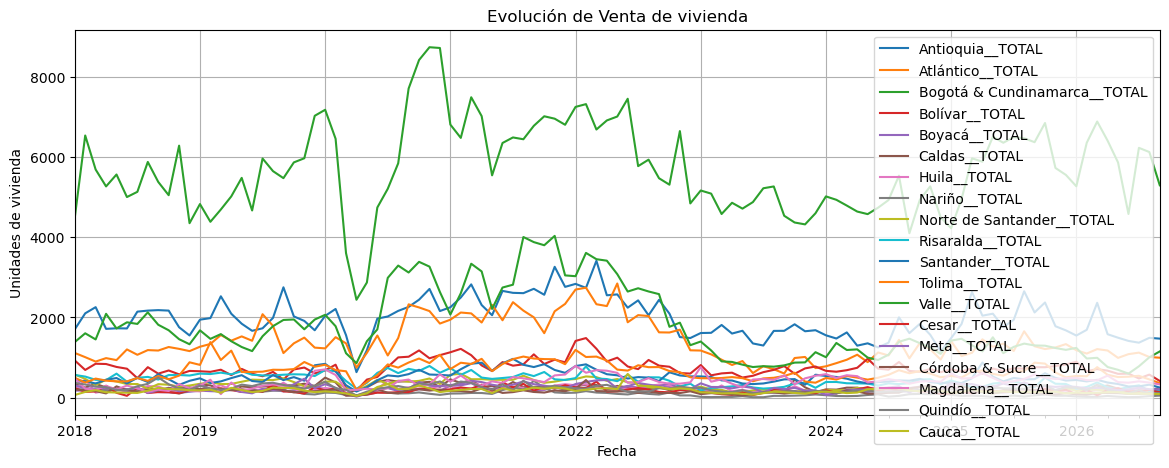

In [135]:
df_ventas.plot(
    figsize=(14, 5),
    title='Evolución de Venta de vivienda',
    xlabel='Fecha',
    ylabel='Unidades de vivienda',
    grid=True
)

plt.show()

### Oferta

In [136]:
df_o.head(10)

,Unidades de vivienda,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161
0,Fuente: Coordenada Urbana,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fecha,Antioquia,NaN,NaN,NaN,NaN,NaN,NaN,Atlántico,NaN,...,NaN,NaN,NaN,19 Regionales,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),...,VIS,NO VIS,TOTAL,VIP,VIS (sin VIP),> VIS y hasta 500 smml,Mayor a 500 smml,VIS,NO VIS,TOTAL
5,2010-01-01 00:00:00,6,1877,4353,1516,1883,5869,7752,2,1486,...,18886,33011,51897,902,17984,23514,9497,18886,33011,51897
6,2010-02-01 00:00:00,6,1848,4750,1629,1854,6379,8233,1,1121,...,19783,32916,52699,1479,18304,23277,9639,19783,32916,52699
7,2010-03-01 00:00:00,5,1876,4974,1711,1881,6685,8566,1,880,...,20124,33112,53236,1425,18699,23736,9376,20124,33112,53236
8,2010-04-01 00:00:00,3,2108,4902,1724,2111,6626,8737,0,831,...,20264,33339,53603,2095,18169,23876,9463,20264,33339,53603
9,2010-05-01 00:00:00,5,2280,5315,1727,2285,7042,9327,0,927,...,20680,33957,54637,1926,18754,24369,9588,20680,33957,54637


In [137]:
df_o.tail(10)

,Unidades de vivienda,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 152,Unnamed: 153,Unnamed: 154,Unnamed: 155,Unnamed: 156,Unnamed: 157,Unnamed: 158,Unnamed: 159,Unnamed: 160,Unnamed: 161
204,2026-08-01 00:00:00,592,8839,11002,2554,9431,13556,22987,2634,4169,...,95145,64023,159168,15448,80468,53600,10796,95916,64396,160312
205,2026-09-01 00:00:00,591,9604,11128,2695,10195,13823,24018,2631,4177,...,93941,64206,158147,14990,79661,53845,10725,94651,64570,159221
206,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
207,2025-09-01 00:00:00,295,8263,9289,4479,8558,13768,22326,2194,5266,...,95588,65031,160619,12761,83939,49853,15393,96700,65246,161946
208,2026-09-01 00:00:00,591,9604,11128,2695,10195,13823,24018,2631,4177,...,93941,64206,158147,14990,79661,53845,10725,94651,64570,159221
209,var anual%,1.00339,0.16229,0.197976,-0.398303,0.191283,0.003995,0.075786,0.19918,-0.206798,...,-0.01723,-0.012686,-0.01539,0.174673,-0.050966,0.080075,-0.303255,-0.021189,-0.010361,-0.016827
210,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
211,2025-12-01 00:00:00,240,7713,8862,4526,7953,13388,21341,2150,4983,...,95937,65363,161300,12928,84116,49390,16280,97044,65670,162714
212,2026-09-01 00:00:00,591,9604,11128,2695,10195,13823,24018,2631,4177,...,93941,64206,158147,14990,79661,53845,10725,94651,64570,159221
213,var año corrido%,1.4625,0.24517,0.255698,-0.404551,0.281906,0.032492,0.125439,0.223721,-0.16175,...,-0.020805,-0.017701,-0.019547,0.159499,-0.052963,0.0902,-0.341216,-0.024659,-0.01675,-0.021467


In [138]:
# Fila que contiene las regionales
regionales_of = df_o.iloc[3].ffill()
# Fila que contiene las categorías de vivienda
categorias_of = df_o.iloc[4]
# Construir nombres de columnas
columnas_of = ['Fecha']

for i in range(1, df_o.shape[1]):
    regional_of = str(regionales_of.iloc[i]).strip()
    categoria_of = str(categorias_of.iloc[i]).strip()

    columnas_of.append(f'{regional_of}__{categoria_of}')

In [139]:
df_ofertas = df_o.iloc[5:-8].copy()
df_ofertas.columns = columnas_of
df_ofertas.reset_index(drop=True, inplace=True)
df_ofertas=df_ofertas.set_index("Fecha")

C:\Users\57302\anaconda3\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [140]:
df_ofertas.index = pd.to_datetime(df_ofertas.index)
df_ofertas.index.name = "Fecha"

In [141]:
df_ofertas.columns

Index(['Antioquia__VIP', 'Antioquia__VIS (sin VIP)',
       'Antioquia__> VIS y hasta 500 smml', 'Antioquia__Mayor a 500 smml',
       'Antioquia__VIS', 'Antioquia__NO VIS', 'Antioquia__TOTAL',
       'Atlántico__VIP', 'Atlántico__VIS (sin VIP)',
       'Atlántico__> VIS y hasta 500 smml',
       ...
       '18 Regionales__VIS', '18 Regionales__NO VIS', '18 Regionales__TOTAL',
       '19 Regionales__VIP', '19 Regionales__VIS (sin VIP)',
       '19 Regionales__> VIS y hasta 500 smml',
       '19 Regionales__Mayor a 500 smml', '19 Regionales__VIS',
       '19 Regionales__NO VIS', '19 Regionales__TOTAL'],
      dtype='object', length=161)

In [142]:
df_ofertas = df_ofertas.loc[
    :,
    [
        col for col in df_ofertas.columns
        if (
            col == "Fecha"
            or (
                col.strip().endswith("__TOTAL")
                and not any(
                    col.startswith(regional + "__")
                    for regional in columnas_agrupadas
                )
            )
        )
    ]
].copy()

In [143]:
df_ofertas = df_ofertas.loc[df_ofertas.index >= "2018-01-01"].copy()

In [144]:
df_ofertas.shape

(105, 19)

In [145]:
df_ofertas.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 105 entries, 2018-01-01 to 2026-09-01
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   Antioquia__TOTAL              105 non-null    object
 1   Atlántico__TOTAL              105 non-null    object
 2   Bogotá & Cundinamarca__TOTAL  105 non-null    object
 3   Bolívar__TOTAL                105 non-null    object
 4   Boyacá__TOTAL                 105 non-null    object
 5   Caldas__TOTAL                 105 non-null    object
 6   Huila__TOTAL                  105 non-null    object
 7   Nariño__TOTAL                 105 non-null    object
 8   Norte de Santander__TOTAL     105 non-null    object
 9   Risaralda__TOTAL              105 non-null    object
 10  Santander__TOTAL              105 non-null    object
 11  Tolima__TOTAL                 105 non-null    object
 12  Valle__TOTAL                  105 non-null    object
 13  C

In [146]:
df_ofertas = df_ofertas.astype('Int64')

In [147]:
df_ofertas.head(5)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2018-01-01,20528,9517,43270,8198,2579,2253,3312,2917,3585,5209,7746,3460,12724,1382,1975,2752,3104,4801,1337
2018-02-01,21498,8843,44622,8446,2662,2125,2858,2994,3282,5181,7899,3755,12723,1318,1893,2561,2937,4550,1782
2018-03-01,23564,9619,42116,8493,2670,2189,2760,3068,3018,5283,7721,3982,13254,1357,1916,2578,3005,3477,1711
2018-04-01,22784,10396,40960,8414,2719,2195,2709,2895,2967,5025,7503,3784,13644,1413,1800,2435,3046,3857,2122
2018-05-01,23444,11139,40992,8070,2720,2464,2723,2691,2893,6572,8049,3651,12382,1352,1910,2467,3258,3829,2027


In [148]:
df_ofertas.tail(10)

,Antioquia__TOTAL,Atlántico__TOTAL,Bogotá & Cundinamarca__TOTAL,Bolívar__TOTAL,Boyacá__TOTAL,Caldas__TOTAL,Huila__TOTAL,Nariño__TOTAL,Norte de Santander__TOTAL,Risaralda__TOTAL,Santander__TOTAL,Tolima__TOTAL,Valle__TOTAL,Cesar__TOTAL,Meta__TOTAL,Córdoba & Sucre__TOTAL,Magdalena__TOTAL,Quindío__TOTAL,Cauca__TOTAL
Fecha,,,,,,,,,,,,,,,,,,,
2025-12-01,21341,10226,56539,9266,2709,2664,2918,576,2614,5274,6358,6069,15856,2283,6578,1502,5867,2660,1414
2026-01-01,20650,10679,55188,9440,2717,2522,2787,560,2552,5116,6446,5874,15086,2238,6375,1510,6372,2572,1474
2026-02-01,21964,10680,55285,9741,2757,2605,2757,567,2585,5112,6227,5599,15568,2115,6532,1517,6107,2540,1459
2026-03-01,21937,11158,54715,9500,2783,2609,2347,548,2493,5284,5490,5378,16841,2088,6437,1492,6983,2790,1480
2026-04-01,21248,11175,53783,9491,2768,2504,2143,513,2564,5570,5212,5219,17633,2040,6240,1512,7157,2735,1365
2026-05-01,22024,10988,53735,9927,2808,2479,2428,595,2514,5717,5224,5060,17319,2165,6204,1514,7433,2698,1181
2026-06-01,21909,10862,53636,10709,2811,2925,2386,690,2606,5936,5125,5154,17304,2075,6050,1481,7505,2615,1098
2026-07-01,23326,10471,53250,10539,2669,2699,2238,722,2537,6247,5196,5068,17014,1942,5932,1441,7088,2602,1166
2026-08-01,22987,10110,52613,10520,2617,2795,2161,692,2489,6429,5043,5275,16810,2021,5830,1414,6828,2534,1144


In [149]:
df_of_stats=df_ofertas.describe().T
df_of_stats.style.format("{:,.2f}")

,count,mean,std,min,25%,50%,75%,max
Antioquia__TOTAL,105.00,"22,795.49","1,593.68","18,340.00","21,922.00","22,606.00","24,074.00","26,561.00"
Atlántico__TOTAL,105.00,"12,622.95","2,187.13","8,843.00","10,718.00","12,358.00","14,028.00","18,114.00"
Bogotá & Cundinamarca__TOTAL,105.00,"57,452.10","9,713.67","40,451.00","49,894.00","58,036.00","66,308.00","73,900.00"
Bolívar__TOTAL,105.00,"9,610.33","1,009.99","7,892.00","8,937.00","9,374.00","9,927.00","12,262.00"
Boyacá__TOTAL,105.00,"2,336.51",301.10,"1,657.00","2,103.00","2,346.00","2,616.00","2,833.00"
Caldas__TOTAL,105.00,"2,454.17",385.67,"1,636.00","2,125.00","2,460.00","2,724.00","3,455.00"
Huila__TOTAL,105.00,"2,657.62",463.00,"1,570.00","2,319.00","2,623.00","2,890.00","3,649.00"
Nariño__TOTAL,105.00,"1,308.89",782.06,272.00,627.00,924.00,"1,902.00","3,068.00"
Norte de Santander__TOTAL,105.00,"2,788.70",361.72,"2,183.00","2,534.00","2,738.00","3,018.00","3,852.00"
Risaralda__TOTAL,105.00,"4,800.55","1,263.44","2,014.00","3,904.00","5,057.00","5,778.00","6,698.00"


In [150]:
df_ofertas.isna().sum()

Antioquia__TOTAL                0
Atlántico__TOTAL                0
Bogotá & Cundinamarca__TOTAL    0
Bolívar__TOTAL                  0
Boyacá__TOTAL                   0
Caldas__TOTAL                   0
Huila__TOTAL                    0
Nariño__TOTAL                   0
Norte de Santander__TOTAL       0
Risaralda__TOTAL                0
Santander__TOTAL                0
Tolima__TOTAL                   0
Valle__TOTAL                    0
Cesar__TOTAL                    0
Meta__TOTAL                     0
Córdoba & Sucre__TOTAL          0
Magdalena__TOTAL                0
Quindío__TOTAL                  0
Cauca__TOTAL                    0
dtype: int64

In [151]:
df_ofertas.index.duplicated().sum()

np.int64(0)

In [152]:
fechas_esperadas = pd.date_range(
    start=df_ofertas.index.min(),
    end=df_ofertas.index.max(),
    freq='MS'
)

fechas_faltantes = fechas_esperadas.difference(df_ofertas.index)

print(fechas_faltantes)

DatetimeIndex([], dtype='datetime64[ns]', freq='MS')


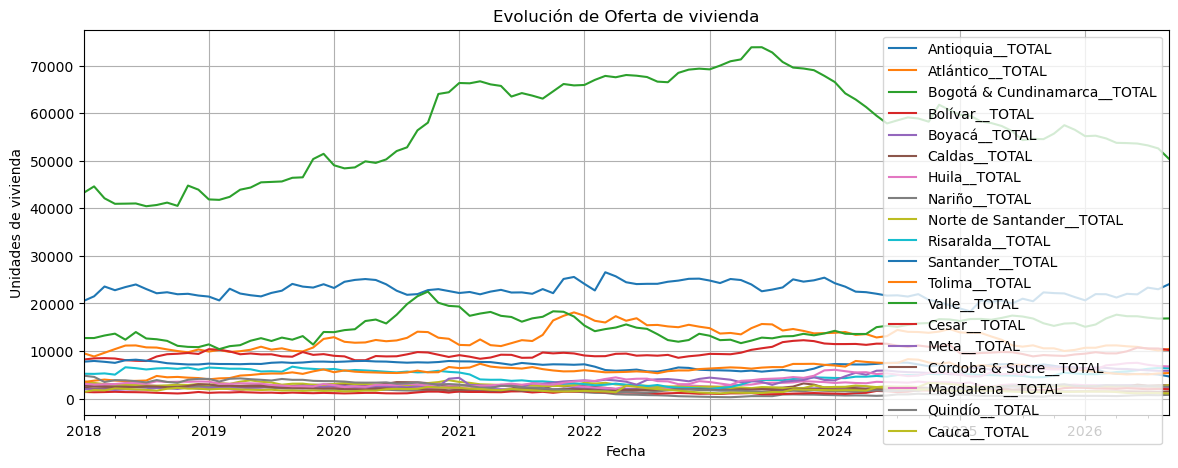

In [153]:
df_ofertas.plot(
    figsize=(14, 5),
    title='Evolución de Oferta de vivienda',
    xlabel='Fecha',
    ylabel='Unidades de vivienda',
    grid=True
)

plt.show()

# Caracteristicas Calidad de Datos

Los datos trabajados en esta sección provienen de un archivo de Excel, el cual esta organizado en diferentes hojas, separando así los temas abordados. En el proceso de revisión evidenciamos que hay presencia de filas vacías (con el fin de hacer más fácil la lectura del archivo), así como columnas combinadas en el Excel, por lo cual, durante el proceso de almacenamiento de esta información en un dataframe se generan múltiples valores nulos.

Adicionalmente, al final del archivo se presentan algunos resúmenes de las variaciones de los últimos periodos.

Presentamos los principales hallazgos del proceso de revisión de los datos:

- No se evidencia presencia de valores nulos relacionados con los datos originales. Los valores nulos que se presentan hacen referencia a columnas combinadas o filas vacías en el archivo de Excel original.
- Evidenciamos continuidad temporal en los datos, es decir, no se registran meses faltantes para ninguna de las tablas de contingencia.
- No se observan fechas duplicadas en una misma tabla de contingencia. 
- La base contempla principalmente dos tipos de datos:

      * Fechas: Corresponde al índice de la tabla.
      * Numéricas: Corresponden a las cantidades de viviendas evaluadas a lo largo del archivo.

- Contamos con información de 207 meses, que abarcan el periodo comprendido entre 2008 y 2026 parcialmente.
- Los datos están presentados en un formato consistente, evaluando cantidades unitarias de vivienda. No se evidencian diferencias en escala.


# Proceso de Limpieza

Presentaremos algunas de las evidencias por las que consideramos necesario implementar un proceso de limpieza de datos:

- **Creación de valores nulos y títulos vacíos.** Tras el proceso de almacenamiento de la información de cada tabla de contingencia en un dataframe, se crean valores nulos debido a que en el archivo original hay encabezados con celdas combinadas, además de la presencia de filas vacías para facilitar la lectura.

    Es necesario la eliminación y ajuste de estos nulos dado que son un componente de ruido que puede afectar el uso de los datos.

- **Tipos de datos.** Aunque la información contenida en nuestra base de datos hace referencia a cantidades de vivienda, el dataframe asigna un tipo de dato “object” a todas las columnas, dificultando operaciones matemáticas entre celdas y la generación de gráficos para hacer análisis estadístico.

- **Regiones.** Contamos con información que hace a 19 regiones del país, además de la información agrupada por difentes grupos. Teniendo en cuenta el alcance del proyecto consideramos necesario prescindir de los datos relacionados con agrupaciones. Esto permitiría un uso mas eficiente de los recursos computacionales con los que contamos.

- **Inconsistencia de títulos.** La fila 4 del dataframe corresponde a la regional y la fila 5 hace referencia a las categorías de vivienda pertenecientes a la región de la fila 4. Tal y como se evidencia en la siguiente imagen, se presenta una inconsistencia en los títulos que dificultará la identificación de los datos asociados a cada región

- **Creación de Índice.** Cada fila de la base hace referencia a un mes dentro del periodo analizado, por tanto, es necesario indicar que la primera columna corresponde al índice de nuestro dataframe. 

- **Información Dispersa.** Se cuenta con información en 4 dataframe diferentes (uno por cada hoja del archivo de Excel original), por lo cual es necesario consolidar la información en un solo dataframe, con el objetivo de simplificar y facilitar su futuro procesamiento como insumo de la solución analítica. Esta unión de dataframes se puede hacer a través del índice fecha. 

- **Exceso de desagregación de cantidades de vivienda.** Como mencionamos anteriormente, contamos con 7 niveles de agregación de las cantidades de vivienda reportadas. Teniendo en cuenta el alcance del proyecto, se recomienda hacer uso únicamente de las cantidades totales de viviendas, sin diferenciar de acuerdo con su naturaleza.

- **Temporalidad.** La base cuenta con información desde el 2006, sin embargo, dado el alcance del proyecto, tomaremos unicamente la información desde 2018 en adelante



Tras el proceso de limpieza anteriormente descrito llegaremos a la creación de un dataframe que cuenta con las siguientes características:

- **Índice:** Fecha.
- **Columnas (76):** Lanzamientos, Iniciaciones, Ventas y Oferta para cada una de las 19 regionales geograficas.
- **Número de registros:** 105


# Creación Base Consolidada

In [155]:
df_coyuntura = pd.concat(
    [
        df_lanzamientos.add_prefix("Lanzamientos__"),
        df_iniciaciones.add_prefix("Iniciaciones__"),
        df_ventas.add_prefix("Ventas__"),
        df_ofertas.add_prefix("Oferta__")
    ],
    axis=1,
    join="outer"
).sort_index()

In [156]:
print("Dimensiones:", df_coyuntura.shape)

print("\nNúmero de columnas por indicador:")
print(df_coyuntura.columns.str.split("__").str[0].value_counts())

print("\nFechas:")
print(df_coyuntura.index.min(), "-", df_coyuntura.index.max())

Dimensiones: (105, 76)

Número de columnas por indicador:
Lanzamientos    19
Iniciaciones    19
Ventas          19
Oferta          19
Name: count, dtype: int64

Fechas:
2018-01-01 00:00:00 - 2026-09-01 00:00:00


In [160]:
df_coyuntura_nacional = pd.DataFrame(index=df_coyuntura.index)

df_coyuntura_nacional["Lanzamientos"] = (df_coyuntura.filter(like="Lanzamientos__").sum(axis=1, min_count=1))
df_coyuntura_nacional["Iniciaciones"] = (df_coyuntura.filter(like="Iniciaciones__").sum(axis=1, min_count=1))
df_coyuntura_nacional["Ventas"] = (df_coyuntura.filter(like="Ventas__").sum(axis=1, min_count=1))
df_coyuntura_nacional["Oferta"] = (df_coyuntura.filter(like="Oferta__").sum(axis=1, min_count=1))

In [162]:
display(df_coyuntura_nacional.head())

print(df_coyuntura_nacional.shape)
print(df_coyuntura_nacional.isna().sum())

,Lanzamientos,Iniciaciones,Ventas,Oferta
Fecha,,,,
2018-01-01,11581,15357,14263,140649
2018-02-01,17303,12716,16058,141929
2018-03-01,15482,12116,14781,141781
2018-04-01,12096,9014,14796,140668
2018-05-01,15089,8087,14538,142633


(105, 4)
Lanzamientos    0
Iniciaciones    0
Ventas          0
Oferta          0
dtype: int64


In [161]:
df_coyuntura_nacional

,Lanzamientos,Iniciaciones,Ventas,Oferta
Fecha,,,,
2018-01-01,11581,15357,14263,140649
2018-02-01,17303,12716,16058,141929
2018-03-01,15482,12116,14781,141781
2018-04-01,12096,9014,14796,140668
2018-05-01,15089,8087,14538,142633
...,...,...,...,...
2026-05-01,10912,10653,12732,162013
2026-06-01,9037,6377,11036,162877
2026-07-01,9244,10545,12992,162147


## Entendimiento de Datos 

Iniciamos el proceso de entendimiento de los datos mediante la revisión de las principales métricas estadísticas del conjunto de datos. A partir de esta exploración, evidenciamos los siguientes comportamientos:

**Lanzamientos**
- Se observa un valor máximo de 28.512 unidades, equivalente a aproximadamente 1,70 veces el valor del percentil 75 (16.755 unidades). Esta diferencia sugiere la posible presencia de observaciones extremas en la parte superior de la distribución.
- La media (14.340 unidades) y la mediana (13.870 unidades) presentan valores cercanos, lo que evidencia una distribución relativamente equilibrada alrededor de su valor central.
- La desviación estándar equivale aproximadamente al 32,94 % de la media, lo que refleja una dispersión considerable de los datos.
- Las diferencias entre los percentiles 25, 50 y 75 son relativamente homogéneas, con incrementos de 3.050 y 2.885 unidades, respectivamente.

**Iniciaciones**
- Se registra un valor máximo de 21.027 unidades, equivalente a aproximadamente 1,45 veces el valor del percentil 75 (14.460 unidades), lo que sugiere la posible presencia de observaciones extremas en la parte superior de la distribución.
- La media (12.247 unidades) y la mediana (12.380 unidades) presentan valores relativamente cercanos, lo que refleja una distribución equilibrada alrededor de su valor central.
- La desviación estándar representa aproximadamente el 26,47 % de la media, lo que indica una dispersión considerable, aunque inferior a la observada en los lanzamientos.
- Las diferencias entre los percentiles 25, 50 y 75 son relativamente homogéneas, con incrementos de 2.328 y 2.080 unidades, respectivamente.

**Ventas**
- El valor máximo registrado es de 24.218 unidades, equivalente a aproximadamente 1,39 veces el percentil 75 (17.460 unidades). Esta diferencia sugiere la posible presencia de observaciones extremas, aunque debe analizarse con mayor detalle para determinar si corresponden a valores atípicos.
- La media (15.646 unidades) y la mediana (15.002 unidades) presentan valores cercanos.
- La desviación estándar equivale aproximadamente al 23,17 % de la media, lo que representa una dispersión relativa inferior a la observada en los lanzamientos y las iniciaciones.
- Las diferencias entre los percentiles 25, 50 y 75 son de 2.169 y 2.458 unidades, respectivamente. Esto evidencia una distribución relativamente concentrada alrededor de la mediana, con una amplitud ligeramente mayor hacia los percentiles superiores.

**Oferta**
- Se registra un valor máximo de 179.198 unidades, superior al percentil 75 (170.716 unidades), aunque la diferencia representa aproximadamente un 4,97 % de este último. Por tanto, no se observa una separación pronunciada entre los valores máximos y el percentil superior que sugiera, por sí sola, la presencia de observaciones extremas.
- La media (162.241 unidades) es ligeramente inferior a la mediana (165.318 unidades), lo que sugiere una posible asimetría negativa en la distribución.
- La desviación estándar representa aproximadamente el 7,14 % de la media, lo que evidencia una dispersión relativa considerablemente menor que la observada en los otros tres indicadores.
- Las diferencias entre los percentiles 25, 50 y 75 son de 9.665 y 5.398 unidades, respectivamente, lo que refleja una mayor concentración de los valores en el tramo superior de la distribución y una dispersión relativamente reducida alrededor de la mediana.


In [175]:
df_coyuntura_nacional.describe().T

,count,mean,std,min,25%,50%,75%,max
Lanzamientos,105.0,14340.380952,4723.036956,6661.0,10820.0,13870.0,16755.0,28512.0
Iniciaciones,105.0,12246.580952,3242.047711,2865.0,10052.0,12380.0,14460.0,21027.0
Ventas,105.0,15646.104762,3626.204084,6389.0,12833.0,15002.0,17460.0,24218.0
Oferta,105.0,162240.609524,11587.254022,138596.0,155653.0,165318.0,170716.0,179198.0
Año,105.0,2021.885714,2.53936,2018.0,2020.0,2022.0,2024.0,2026.0
Mes,105.0,6.371429,3.428549,1.0,3.0,6.0,9.0,12.0


A partir de las métricas estadísticas revisadas, podemos establecer las siguientes observaciones:

- La oferta presenta una escala considerablemente superior a la de los otros tres indicadores, tanto en términos de promedio como de dispersión absoluta. Sin embargo, registra la menor dispersión relativa, lo que evidencia una mayor concentración de sus valores alrededor de la media.
- Los promedios de lanzamientos, iniciaciones y ventas presentan magnitudes relativamente similares. No obstante, las ventas registran una menor dispersión relativa, lo que sugiere un comportamiento histórico más estable en comparación con los otros dos indicadores.
- Lanzamientos e iniciaciones presentan una mayor diferencia entre sus valores máximos y sus respectivos percentiles superiores, especialmente los lanzamientos, lo que podría indicar la existencia de meses con niveles de actividad particularmente elevados.
- La oferta presenta una media inferior a la mediana, lo que sugiere una posible asimetría negativa en su distribución. Adicionalmente, la proximidad entre el valor máximo y el percentil 75 evidencia una menor separación en la parte superior de la distribución, por lo que resulta conveniente profundizar en el análisis de su comportamiento.


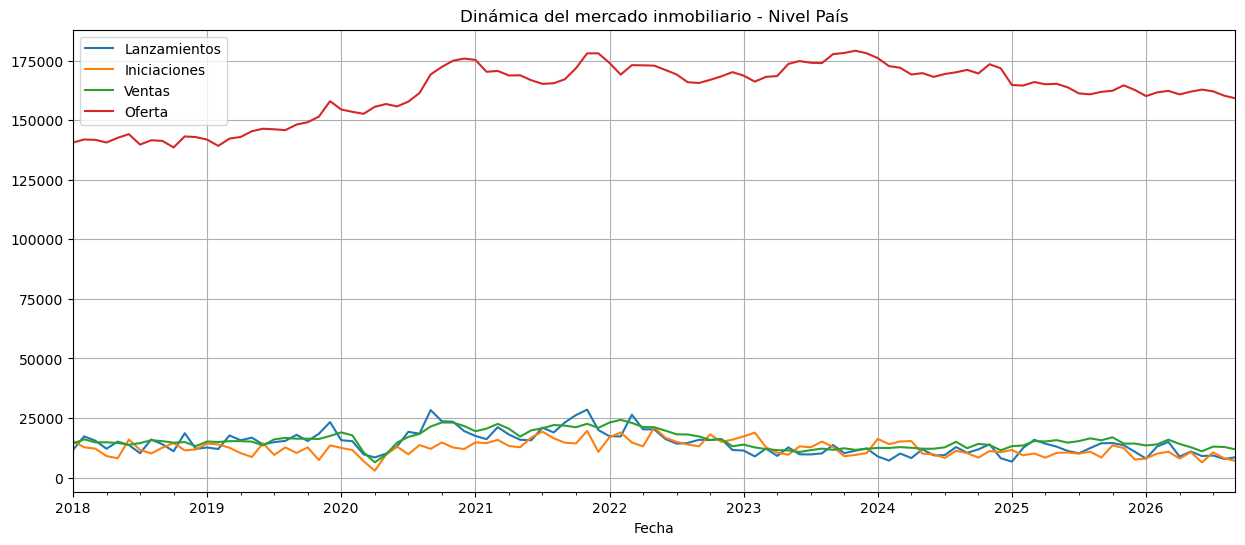

In [163]:
df_coyuntura_nacional.plot(
    figsize=(15, 6),
    title='Dinámica del mercado inmobiliario - Nivel País',
    grid=True
)

plt.show()

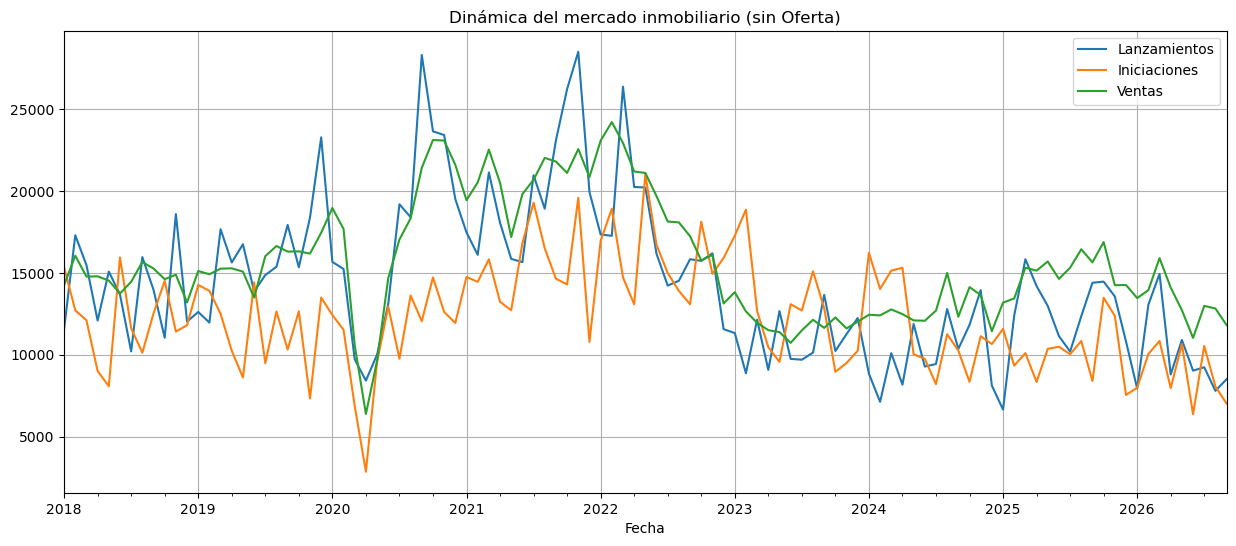

In [164]:
dfmin=df_coyuntura_nacional[['Lanzamientos','Iniciaciones','Ventas']].copy()

dfmin.plot(
    figsize=(15, 6),
    title='Dinámica del mercado inmobiliario (sin Oferta)',
    grid=True
)

plt.show()

A partir de la representación gráfica de las series temporales, podemos identificar diferentes patrones en la evolución de los indicadores del mercado inmobiliario durante los periodos analizados.

**Oferta**
- Se observa una tendencia creciente de la oferta disponible desde el inicio de la serie hasta aproximadamente 2023, cuando alcanza sus niveles más elevados, cercanos a las 180.000 unidades. A partir de ese momento, la tendencia cambia de dirección y comienza una reducción progresiva del inventario disponible, situándose alrededor de las 160.000 unidades hacia el final del periodo analizado. Este comportamiento podría estar relacionado con una desaceleración de la actividad del sector, así como con cambios en las condiciones de financiación y en los programas de acceso a vivienda.
- Entre 2020 y 2021 se registra uno de los incrementos más pronunciados de la serie, seguido de un periodo de niveles elevados que se extiende hasta 2023.
  El crecimiento observado durante este periodo podría estar relacionado con las condiciones favorables de financiación, las políticas de estímulo a la adquisición de vivienda, particularmente mediante el programa "Mi Casa Ya", y la reactivación de la actividad constructora después de las restricciones asociadas a la pandemia. Sin embargo, estos factores deben considerarse como posibles elementos explicativos y no como relaciones causales demostradas por la representación gráfica.

**Lanzamientos**
- Los lanzamientos presentan un comportamiento altamente variable a lo largo del periodo, con fluctuaciones y picos pronunciados, especialmente entre 2020 y 2022, cuando se registran algunos de los niveles más elevados de la serie, cercanos a las 28.000 unidades.
- Se observa una tendencia creciente hasta aproximadamente 2021, cuando se alcanza uno de los niveles más elevados de la serie. Posteriormente, se evidencia una reducción importante de la actividad durante 2023, seguida de fluctuaciones y recuperaciones puntuales durante 2024 y 2025.
- Los incrementos pronunciados suelen estar seguidos de reducciones importantes, lo que refleja una dinámica irregular en la incorporación de nuevos proyectos al mercado. Este comportamiento puede estar relacionado con la sensibilidad de los desarrollos inmobiliarios frente a las condiciones económicas, financieras y comerciales.
- A partir de 2023 se observa una disminución general de los niveles de lanzamientos respecto a los máximos registrados durante 2021 y 2022, aunque se presentan algunas recuperaciones posteriores. Hacia 2026 se evidencia nuevamente una reducción de la actividad.

**Iniciaciones**
- Las iniciaciones presentan un comportamiento fluctuante y, en términos generales, una evolución similar a la de los lanzamientos durante buena parte del periodo, aunque con diferencias en la magnitud y el momento en que se presentan sus variaciones.
Esta relación tiene sentido desde la dinámica del sector, dado que los proyectos que comienzan su comercialización pueden iniciar posteriormente su construcción, una vez cumplen las condiciones comerciales, financieras y técnicas necesarias. Sin embargo, esta correspondencia no es inmediata ni proporcional, debido al desfase temporal entre el lanzamiento comercial y el inicio real del proceso de construcción.
- Alrededor de 2020 se observa una caída pronunciada de las iniciaciones, coincidente con el periodo de restricciones derivadas de la pandemia de COVID-19. Este comportamiento podría estar relacionado con las interrupciones de las actividades constructivas y los aplazamientos en el inicio de nuevos proyectos.
- Posteriormente, se observa una recuperación importante, alcanzando niveles elevados entre 2021 y 2022. Sin embargo, a partir de 2023 se evidencia una reducción de la actividad, con fluctuaciones durante los años siguientes y niveles inferiores a los máximos registrados anteriormente.
  
**Ventas**
- Las ventas presentan una evolución relativamente más estable que los lanzamientos y las iniciaciones durante buena parte del periodo, aunque también registran fluctuaciones pronunciadas en determinados momentos.
- Se observa un comportamiento relativamente estable durante 2018 y 2019, seguido de una caída importante alrededor de 2020, coincidente con el periodo de restricciones asociadas a la pandemia. Posteriormente, las ventas muestran una recuperación significativa, alcanzando niveles elevados entre 2021 y 2022, con valores cercanos a las 24.000 unidades.
- Este crecimiento podría estar relacionado con las medidas de financiación, las políticas de estímulo a la adquisición de vivienda y la rápida reactivación de las actividades del sector después de la pandemia.
- A partir de 2023 se observa una reducción de la actividad comercial, seguida de una recuperación progresiva durante 2024 y 2025, cuando se alcanzan nuevamente niveles cercanos a los registrados en algunos periodos anteriores. Hacia 2026 se evidencia una nueva disminución de las ventas.

Tomando en consideración el comportamiento temporal descrito anteriormente, podemos establecer las siguientes conclusiones:

- La oferta disponible presenta una dinámica diferente a la de los demás indicadores, debido a que representa el inventario de vivienda disponible en el mercado y no un flujo mensual de actividad. Se observa un crecimiento sostenido hasta 2023, seguido de una reducción progresiva del inventario durante los años posteriores.
- Los lanzamientos y las iniciaciones presentan fluctuaciones pronunciadas y una relación temporal que puede estar asociada al proceso de maduración de los proyectos inmobiliarios. Ambos indicadores registran sus mayores niveles entre 2021 y 2022, seguidos de una reducción de la actividad a partir de 2023.
- Las ventas muestran un comportamiento relativamente más estable, aunque también responden a cambios importantes en las condiciones del mercado. Se destaca la recuperación registrada entre 2021 y 2022 y la posterior reducción de la actividad comercial durante 2023.
- La pandemia de COVID-19 coincide con alteraciones relevantes en la dinámica de los indicadores, particularmente en las iniciaciones y las ventas, que presentan reducciones pronunciadas alrededor de 2020, seguidas de una recuperación durante los años posteriores.
- El periodo posterior a 2022 presenta señales de desaceleración en varios indicadores, especialmente en los lanzamientos, las iniciaciones y la oferta disponible. No obstante, las ventas y los lanzamientos presentan recuperaciones puntuales durante 2024 y 2025, lo que evidencia que el comportamiento del mercado no ha seguido una trayectoria uniforme.
 



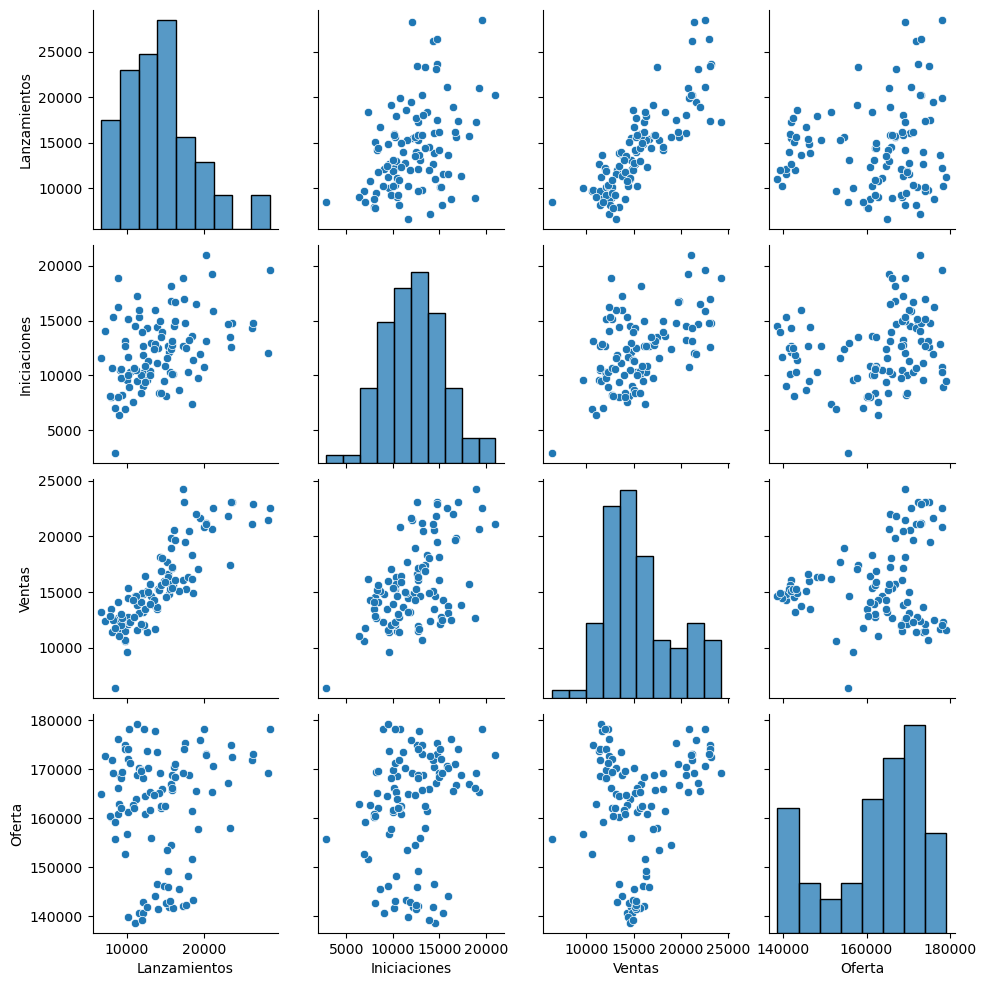

In [165]:
sns.pairplot(df_coyuntura_nacional.select_dtypes(include="number"))
plt.show()

Al analizar los diagramas de dispersión, se identifican diferentes patrones de asociación entre las variables. Se destaca una relación positiva entre los lanzamientos y las ventas, en la cual los incrementos de una variable tienden a estar acompañados por incrementos de la otra. Esta asociación sugiere que los periodos con mayor incorporación de nuevos proyectos al mercado también suelen presentar mayores niveles de comercialización.

Adicionalmente, se observa una asociación positiva entre las iniciaciones y las ventas, aunque con una mayor dispersión de las observaciones, lo que indica una relación menos marcada. Por su parte, la relación entre lanzamientos e iniciaciones también presenta una tendencia positiva, aunque menos pronunciada, lo que puede estar relacionado con los desfases temporales existentes entre la comercialización de los proyectos y el inicio de su construcción.

En cuanto a la oferta, no se identifican relaciones lineales claramente definidas con los demás indicadores. La distribución de las observaciones presenta una mayor dispersión y agrupaciones en diferentes niveles, lo que sugiere que su comportamiento responde a una dinámica distinta a la de los flujos de actividad del mercado.


In [166]:
#matriz de correlación
correlation_matrix = df_coyuntura_nacional.corr()
correlation_matrix

,Lanzamientos,Iniciaciones,Ventas,Oferta
Lanzamientos,1.000000,0.384717,0.838807,0.089667
Iniciaciones,0.384717,1.000000,0.527659,0.220349
Ventas,0.838807,0.527659,1.000000,0.172182
Oferta,0.089667,0.220349,0.172182,1.000000


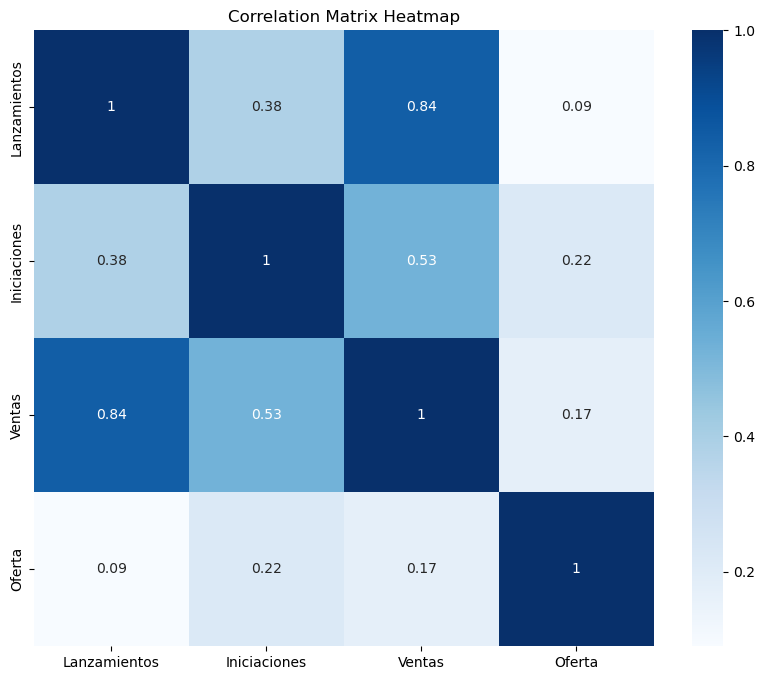

In [167]:
#Mapa de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='Blues')
plt.title('Correlation Matrix Heatmap')
plt.show()

Al complementar esta exploración visual con la matriz de correlación de Pearson, se evidencia que la relación más fuerte **(0,84)** se presenta entre las variables Lanzamientos y Ventas, lo que indica una asociación lineal positiva considerable. Por otra parte, se identifica una relación positiva moderada entre Iniciaciones y Ventas **(0,53)**, mientras que la relación entre Lanzamientos e Iniciaciones **(0,38)** es positiva, aunque de menor intensidad.

En cuanto a la Oferta, se observan correlaciones débiles con los demás indicadores, siendo la relación más alta la presentada con las Iniciaciones **(0,22)**. Estos resultados sugieren que la dinámica de la oferta disponible presenta un comportamiento relativamente independiente de los flujos de actividad del mercado, lo que podría estar relacionado con su naturaleza de inventario y con otros factores que inciden en su evolución.

A continuación, orientamos el análisis hacia la identificación de patrones estacionales, examinando el comportamiento mensual histórico de los diferentes indicadores del mercado inmobiliario. El objetivo es identificar posibles concentraciones de actividad en determinados periodos del año.


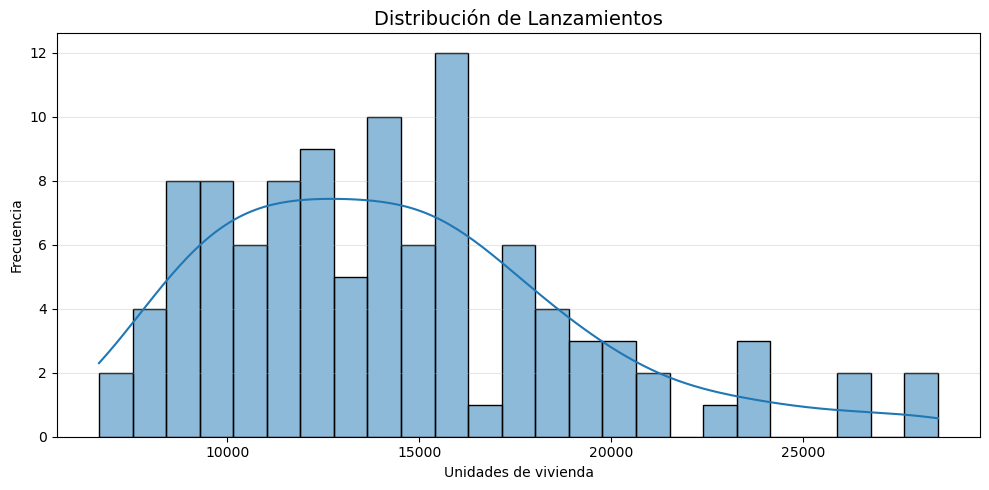

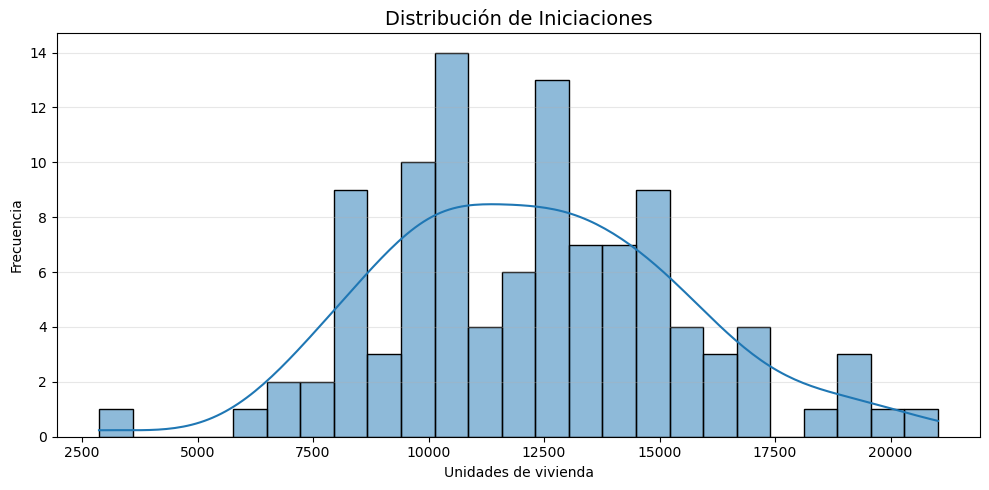

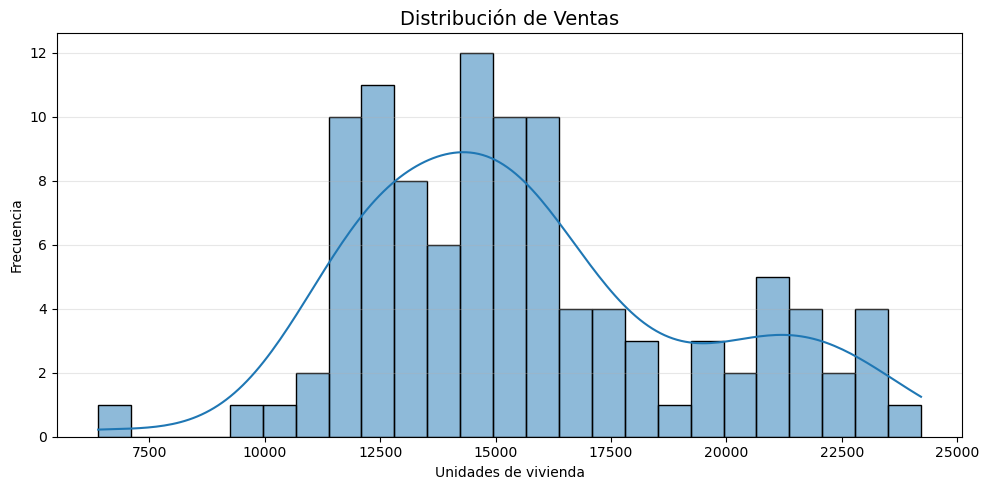

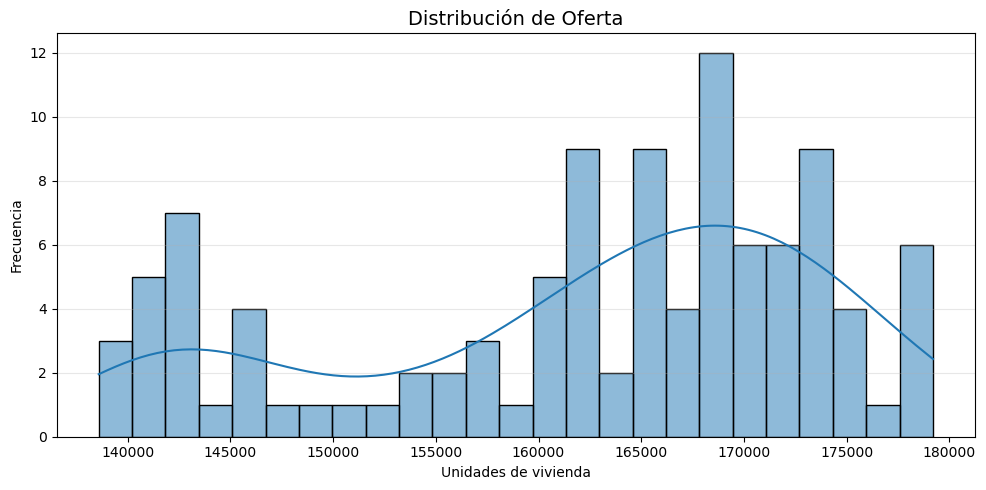

In [168]:
for variable in df_coyuntura_nacional.columns:

    plt.figure(figsize=(10, 5))

    sns.histplot(
        data=df_coyuntura_nacional,
        x=variable,
        bins=25,
        kde=True
    )

    plt.title(f'Distribución de {variable}', fontsize=14)
    plt.xlabel('Unidades de vivienda')
    plt.ylabel('Frecuencia')
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

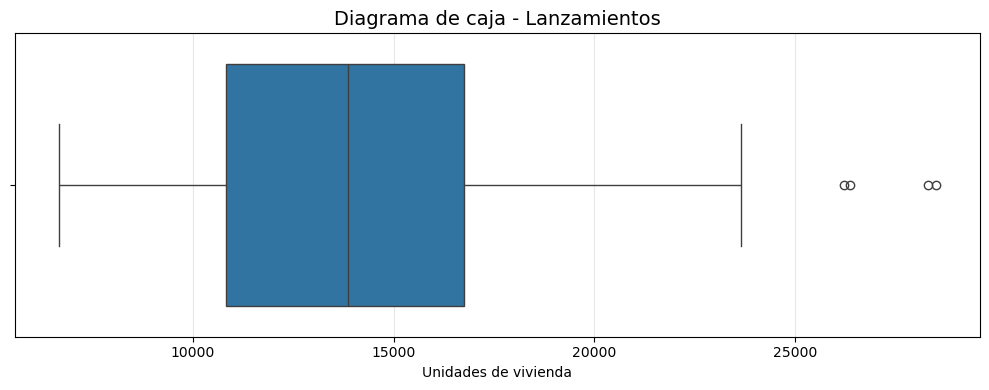

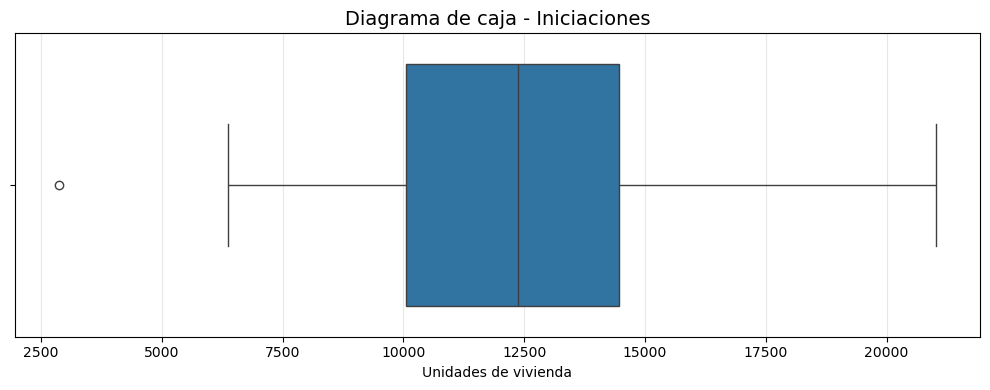

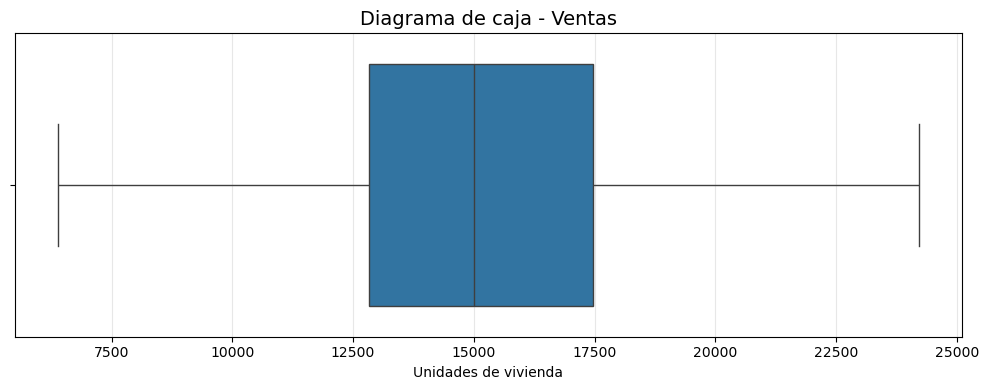

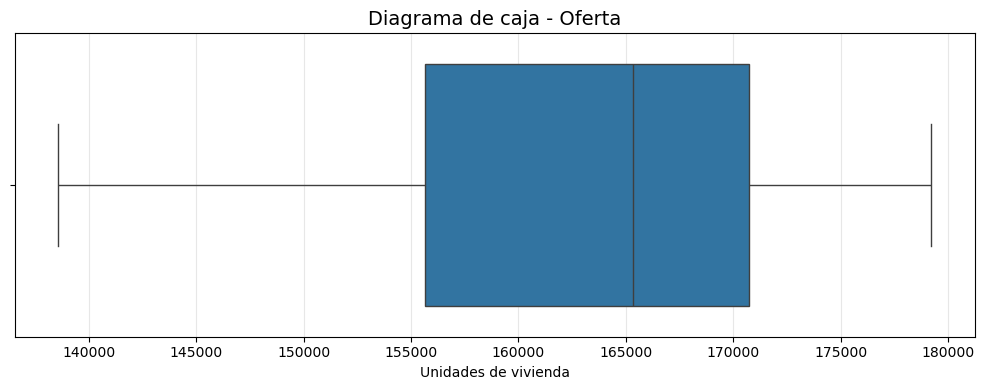

In [169]:
for variable in df_coyuntura_nacional.columns:

    plt.figure(figsize=(10, 4))

    sns.boxplot(
        data=df_coyuntura_nacional,
        x=variable
    )

    plt.title(f'Diagrama de caja - {variable}', fontsize=14)
    plt.xlabel('Unidades de vivienda')

    plt.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

In [170]:
df_coyuntura_nacional['Año'] = df_coyuntura_nacional.index.year
df_coyuntura_nacional['Mes'] = df_coyuntura_nacional.index.month

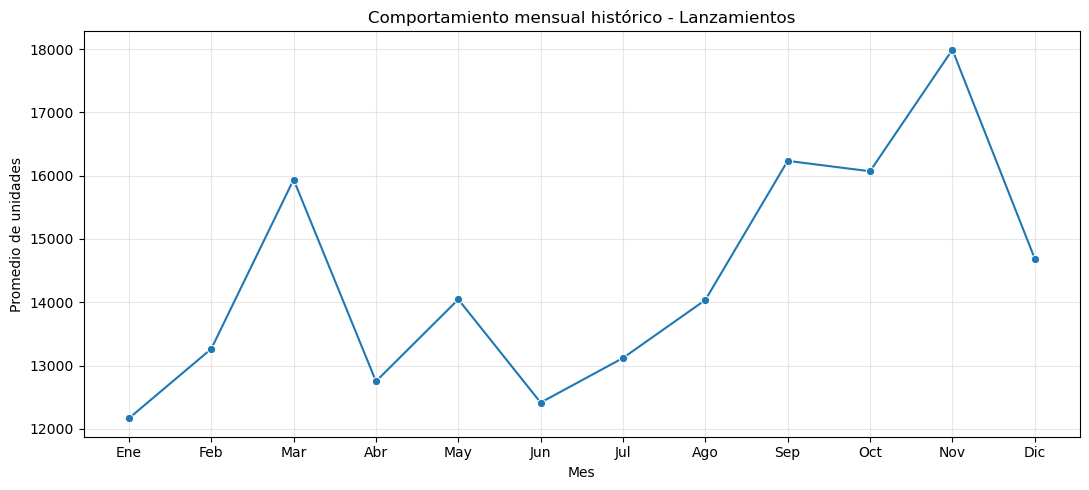

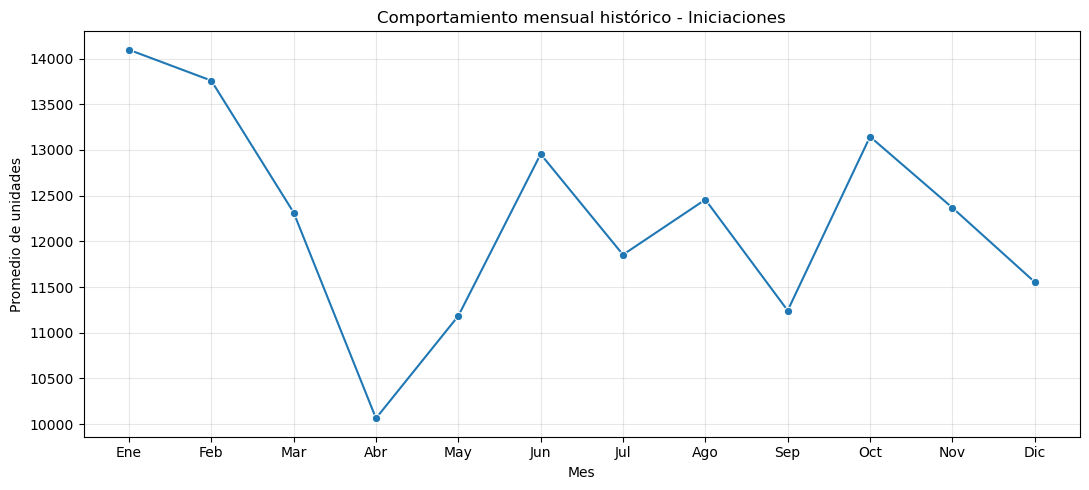

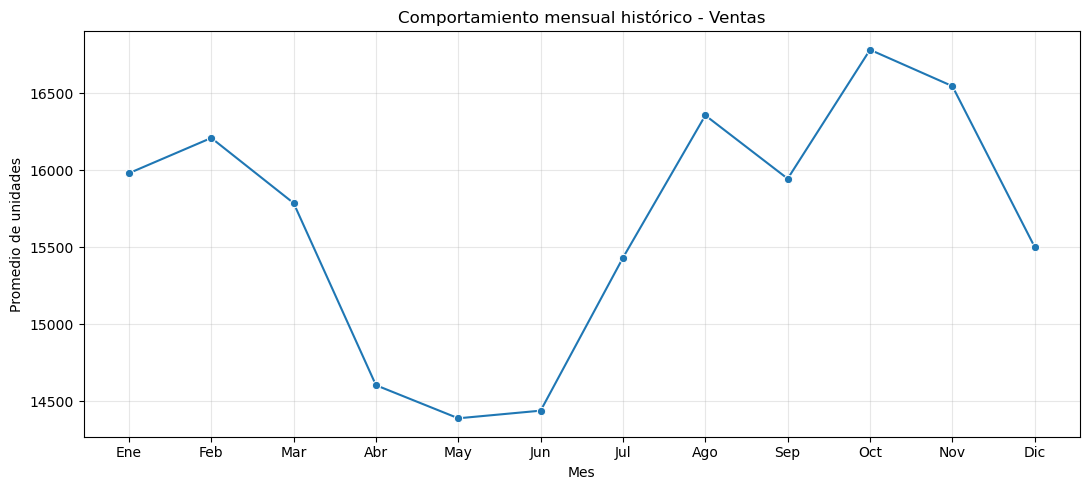

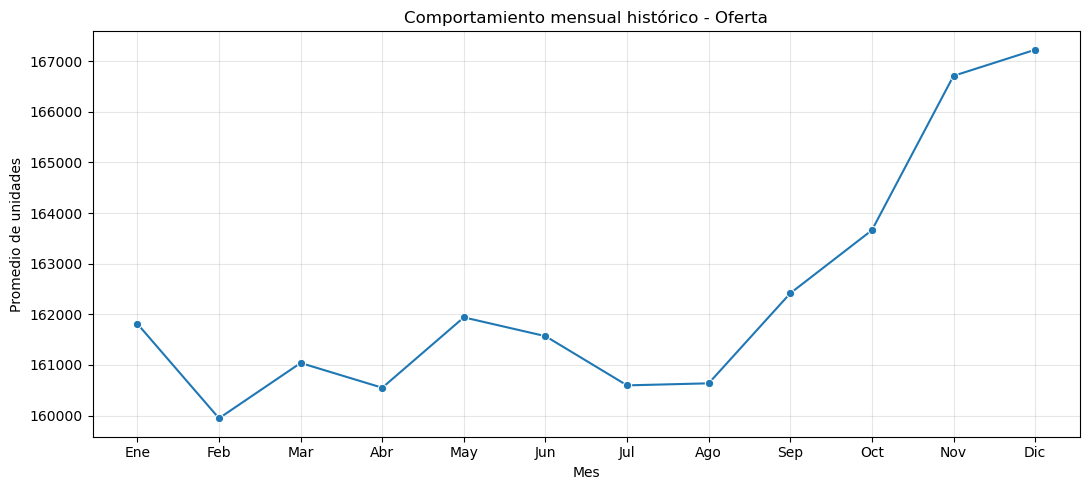

In [171]:
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun','Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

for variable in ['Lanzamientos', 'Iniciaciones', 'Ventas', 'Oferta']:

    promedio = df_coyuntura_nacional.groupby('Mes')[variable].mean()
    plt.figure(figsize=(11, 5))
    sns.lineplot(
        x=promedio.index,
        y=promedio.values,
        marker='o'
    )

    plt.xticks(range(1, 13), meses)
    plt.title(f'Comportamiento mensual histórico - {variable}')
    plt.xlabel('Mes')
    plt.ylabel('Promedio de unidades')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

En el caso de los Lanzamientos, se observa una tendencia a concentrar la incorporación de nuevos proyectos inmobiliarios durante la segunda mitad del año, especialmente entre septiembre y noviembre, siendo este último el mes que registra el mayor promedio histórico, cercano a las 18.000 unidades. Por el contrario, enero y junio presentan los niveles promedio más bajos, con aproximadamente 12.200 y 12.400 unidades, respectivamente.

Este comportamiento podría estar relacionado con factores asociados a la dinámica comercial del sector, la programación de nuevos proyectos y las condiciones económicas propias de cada periodo. Se destaca especialmente el incremento registrado entre agosto y noviembre, lo que sugiere una mayor actividad de lanzamiento de proyectos hacia el cierre del año.

Para la variable de Ventas, se identifica una reducción de los niveles promedio durante el segundo trimestre del año, especialmente entre abril y junio, siendo mayo el mes que registra el menor promedio histórico, cercano a las 14.400 unidades. Posteriormente, se observa una recuperación progresiva durante el segundo semestre, alcanzando sus niveles más elevados en octubre y noviembre, con aproximadamente 16.800 y 16.600 unidades, respectivamente.

Este comportamiento sugiere una posible concentración de la actividad comercial durante la segunda mitad del año, particularmente hacia el último trimestre. No obstante, las diferencias entre algunos meses son relativamente moderadas, por lo que no se evidencia una estacionalidad completamente uniforme.

Las iniciaciones presentan una mayor variabilidad en su comportamiento mensual, sin evidenciar un patrón estacional tan definido como el observado en los lanzamientos. Se destacan los niveles promedio más elevados durante enero y febrero, con aproximadamente 14.100 y 13.800 unidades, respectivamente. Por el contrario, abril registra el menor promedio histórico, cercano a las 10.000 unidades.

Posteriormente, se observa una recuperación durante mayo y junio, seguida de fluctuaciones durante el segundo semestre. Se destaca un nuevo incremento en octubre, cuando se alcanza un promedio cercano a las 13.100 unidades. Esta fluctuación podría estar asociada a la programación de las obras y a las condiciones comerciales, financieras y operativas necesarias para dar inicio a los proyectos inmobiliarios.

Finalmente, la oferta presenta un comportamiento relativamente estable durante la primera mitad del año, con valores promedio que oscilan alrededor de las 160.000 y 162.000 unidades. Sin embargo, a partir de septiembre se observa un incremento progresivo del inventario disponible, alcanzando sus niveles más elevados en noviembre y diciembre, con aproximadamente 166.700 y 167.200 unidades, respectivamente.

Este comportamiento podría indicar una mayor disponibilidad de unidades de vivienda en el mercado durante el cierre del año. A diferencia de los indicadores anteriores, la oferta representa un inventario acumulado, por lo que sus variaciones responden tanto a la incorporación de nuevos proyectos como a la comercialización de las unidades disponibles.


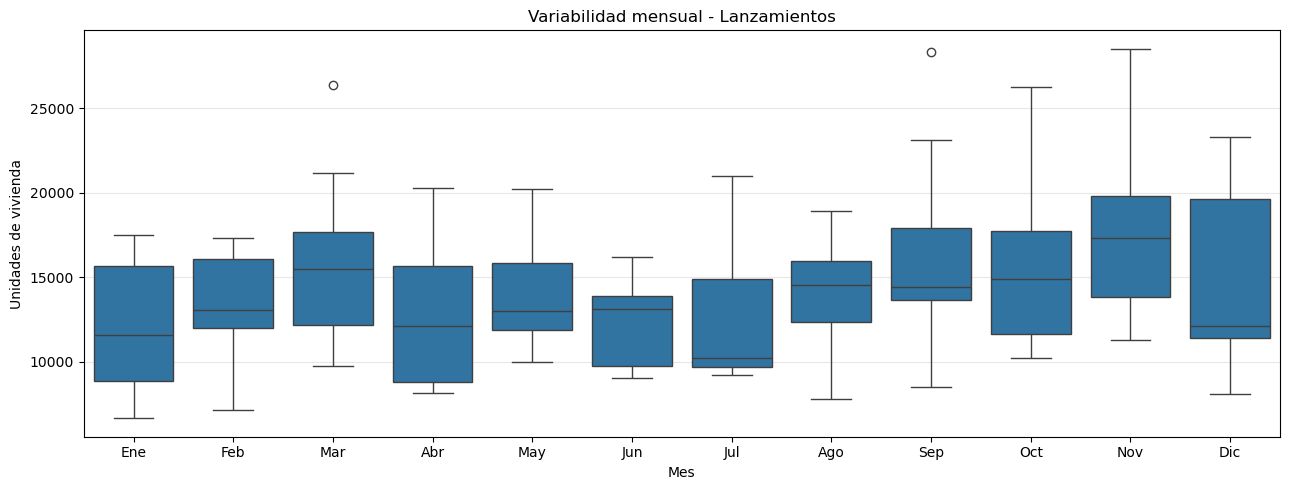

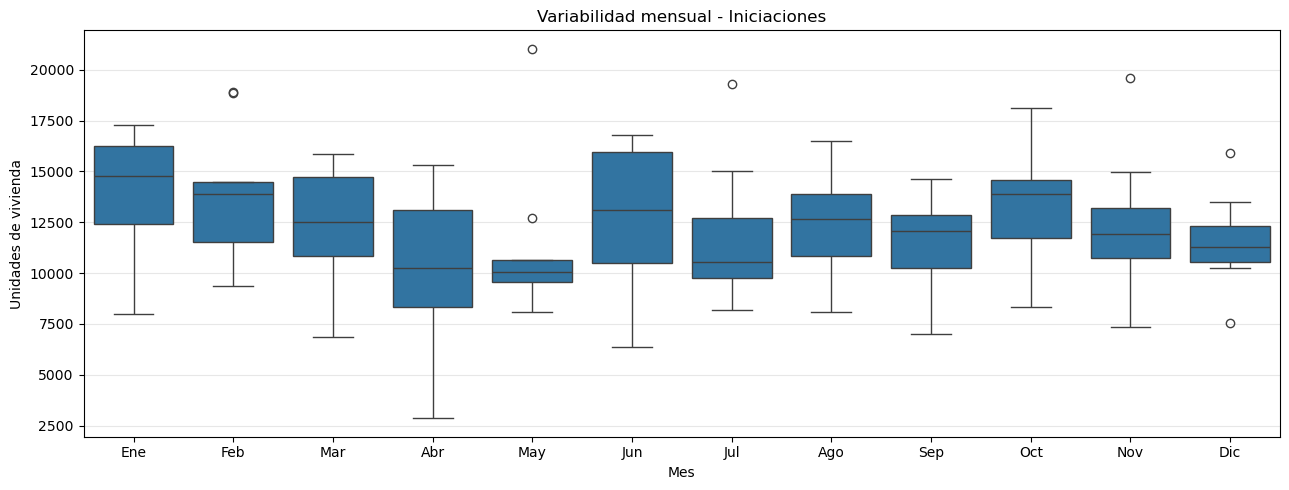

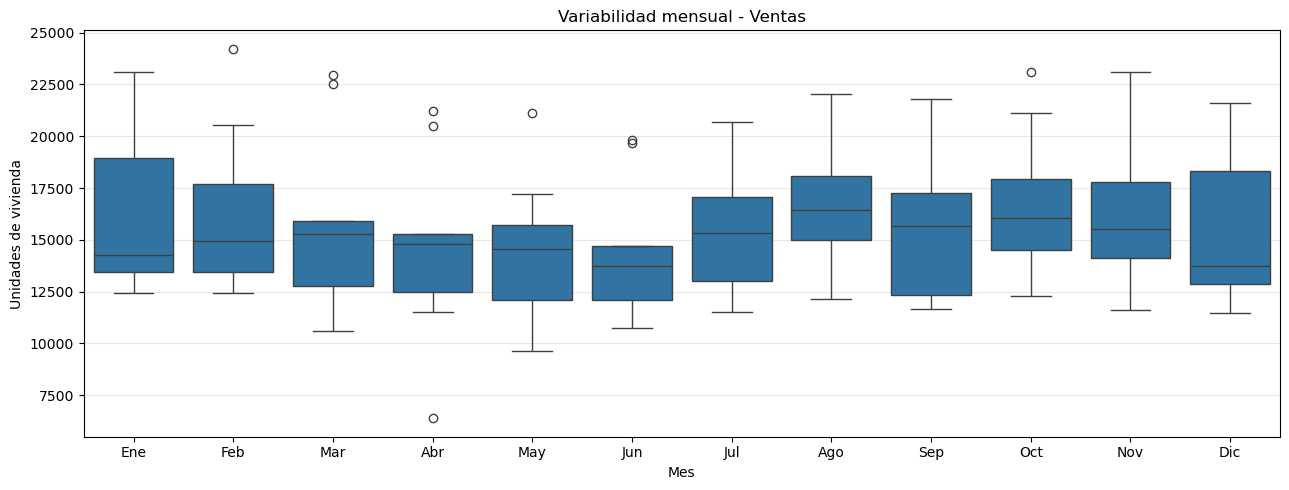

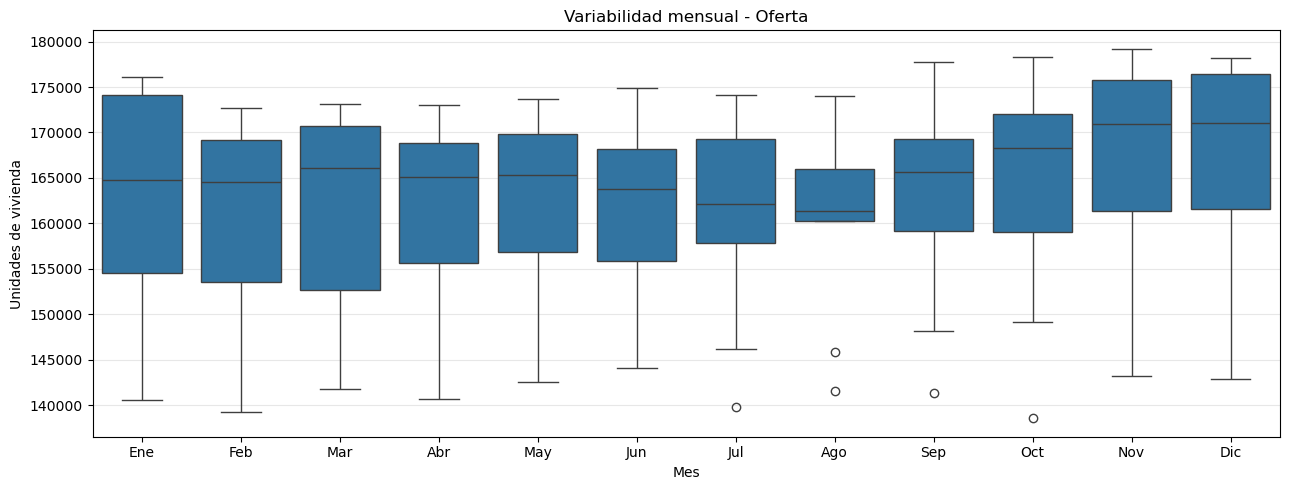

In [172]:
for variable in ['Lanzamientos', 'Iniciaciones', 'Ventas', 'Oferta']:

    plt.figure(figsize=(13, 5))

    sns.boxplot(
        data=df_coyuntura_nacional,
        x='Mes',
        y=variable,
        order=range(1, 13)
    )

    plt.xticks(range(12), meses)
    plt.title(f'Variabilidad mensual - {variable}')
    plt.xlabel('Mes')
    plt.ylabel('Unidades de vivienda')
    plt.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.show()

Para complementar el análisis realizado anteriormente, identificamos ahora el grado de dispersión, concentración y presencia de outliers a nivel mensual, para lo cual tenemos que:

**Lanzamientos**
- Los lanzamientos presentan una dispersión considerable durante la mayoría de los meses, especialmente entre septiembre y diciembre, donde se observan rangos intercuartílicos más amplios. Esto indica una mayor variabilidad en los niveles de incorporación de nuevos proyectos durante estos periodos.
- Noviembre registra una de las medianas más elevadas, lo que coincide con el comportamiento identificado en el análisis de promedios mensuales. Por el contrario, enero y junio presentan valores centrales relativamente inferiores.
- Se identifican valores atípicos en marzo y septiembre, con registros que superan considerablemente los rangos habituales de cada mes. Estas observaciones podrían estar asociadas a periodos particulares de alta actividad en el lanzamiento de proyectos inmobiliarios.

**Iniciaciones**
- Las iniciaciones presentan una variabilidad considerable entre los diferentes meses, aunque con una distribución relativamente más concentrada durante febrero, mayo y septiembre.
- Se observa una mayor dispersión durante enero, abril y junio, lo que evidencia diferencias importantes en los niveles de actividad registrados entre los distintos años. Abril presenta, además, uno de los rangos inferiores más amplios, con registros considerablemente por debajo de su mediana.
- Se identifican valores atípicos en febrero, mayo, julio, noviembre y diciembre, especialmente en mayo, donde se registra una observación superior a las 20.000 unidades. Estas diferencias podrían estar relacionadas con periodos particulares de mayor actividad constructiva.

**Ventas**
- Las ventas presentan una dispersión relativamente amplia durante la mayoría de los meses, aunque se observa una mayor concentración de los registros alrededor de la mediana durante marzo, abril y junio.
- Enero y febrero presentan una variabilidad considerable, con diferencias importantes entre los valores mínimos y máximos registrados. Por su parte, agosto y octubre muestran medianas relativamente elevadas, lo que coincide con los resultados obtenidos en el análisis de promedios mensuales.
- Se identifican valores atípicos en varios meses, particularmente entre febrero y junio, así como en octubre. Estas observaciones reflejan la existencia de periodos con niveles de comercialización considerablemente superiores o inferiores al comportamiento habitual.
Oferta
- La oferta presenta una distribución relativamente estable durante los diferentes meses, con medianas que se mantienen en niveles cercanos, aunque se observa un incremento progresivo hacia noviembre y diciembre.
- Los rangos intercuartílicos presentan una amplitud considerable durante buena parte del año, lo que evidencia diferencias en los niveles de inventario disponible entre los distintos periodos analizados.
- Se identifican algunos valores atípicos en la parte inferior de la distribución, especialmente entre julio y octubre, donde se registran niveles de oferta considerablemente inferiores a los valores centrales de cada mes.
- Noviembre y diciembre presentan las medianas más elevadas, lo que coincide con el incremento del inventario disponible identificado en el análisis mensual histórico.

Tomando en consideración el comportamiento de la dispersión y los valores atípicos descritos anteriormente, podemos establecer las siguientes conclusiones:
- Los lanzamientos y las iniciaciones presentan una variabilidad considerable entre los diferentes meses, lo que evidencia una dinámica de incorporación de nuevos proyectos y actividad constructiva que no se mantiene uniforme a lo largo del tiempo.
- Las ventas presentan diferencias importantes entre los registros de cada mes, aunque se observa una concentración relativamente mayor alrededor de sus valores centrales durante algunos periodos.
- La oferta presenta un comportamiento comparativamente más estable, con medianas relativamente homogéneas y una menor variabilidad en términos relativos, aunque se identifican diferencias en los niveles de inventario entre los distintos años.
- La presencia de valores atípicos en los cuatro indicadores evidencia la existencia de periodos con comportamientos particulares que se alejan de los niveles habituales de actividad. Estas observaciones no necesariamente representan errores en los datos, por lo que resulta conveniente analizarlas considerando las condiciones económicas y sectoriales de cada periodo.



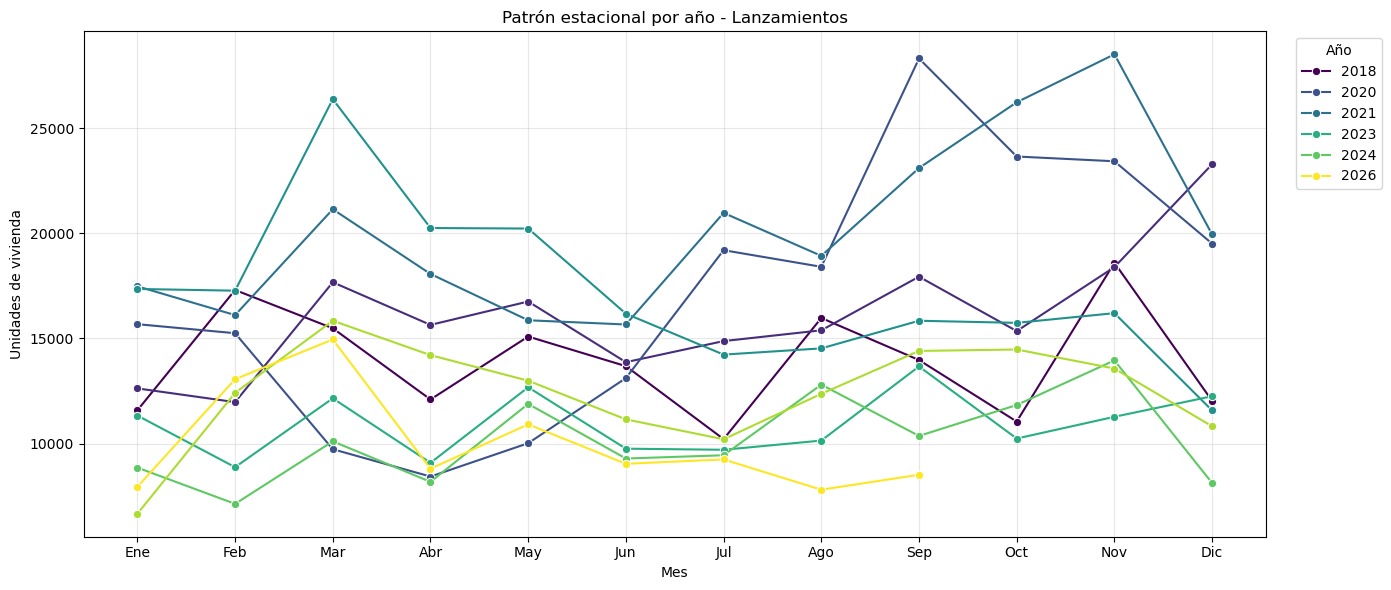

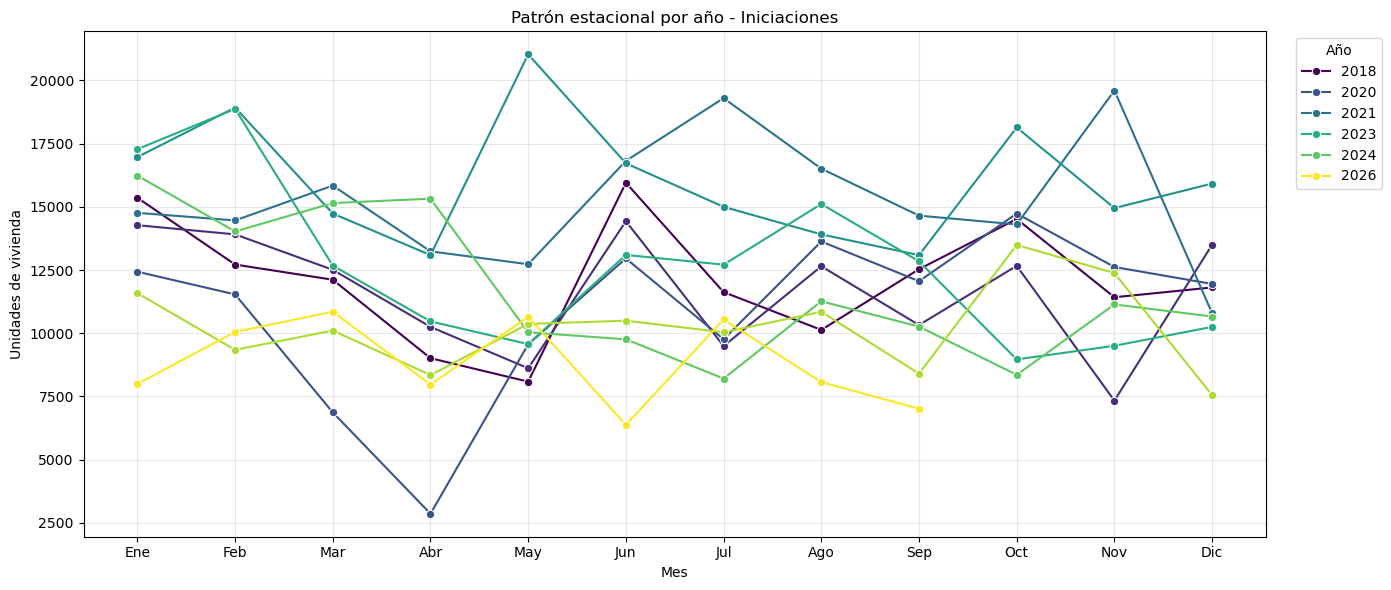

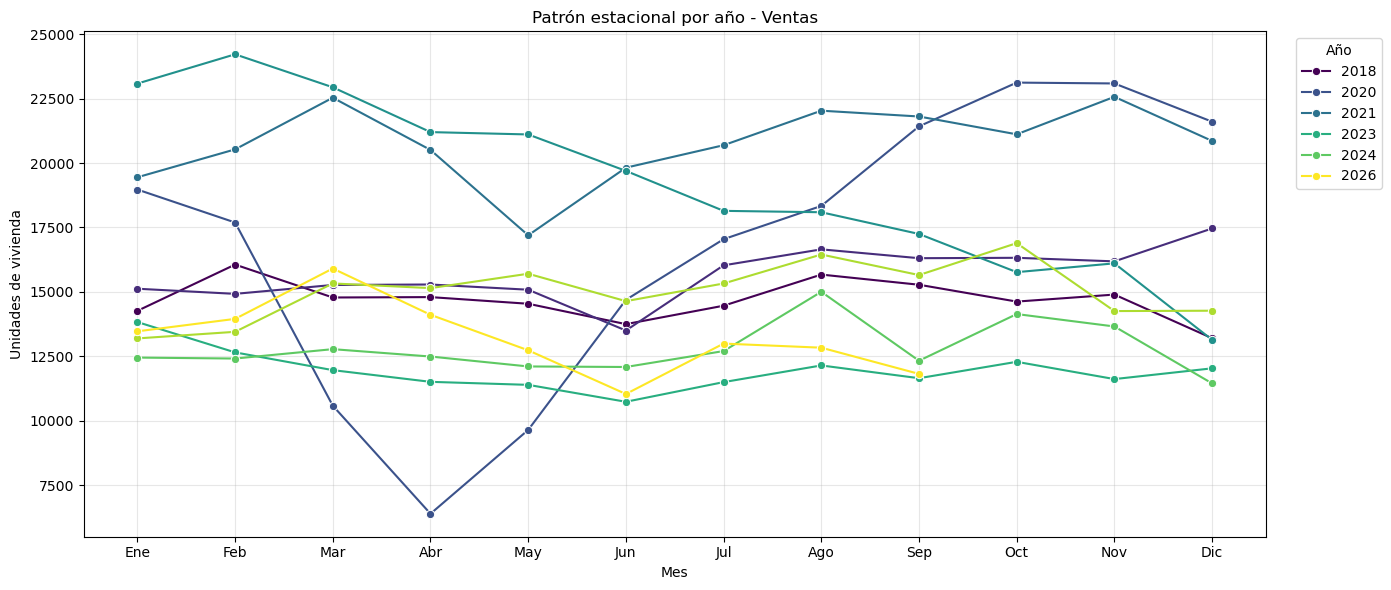

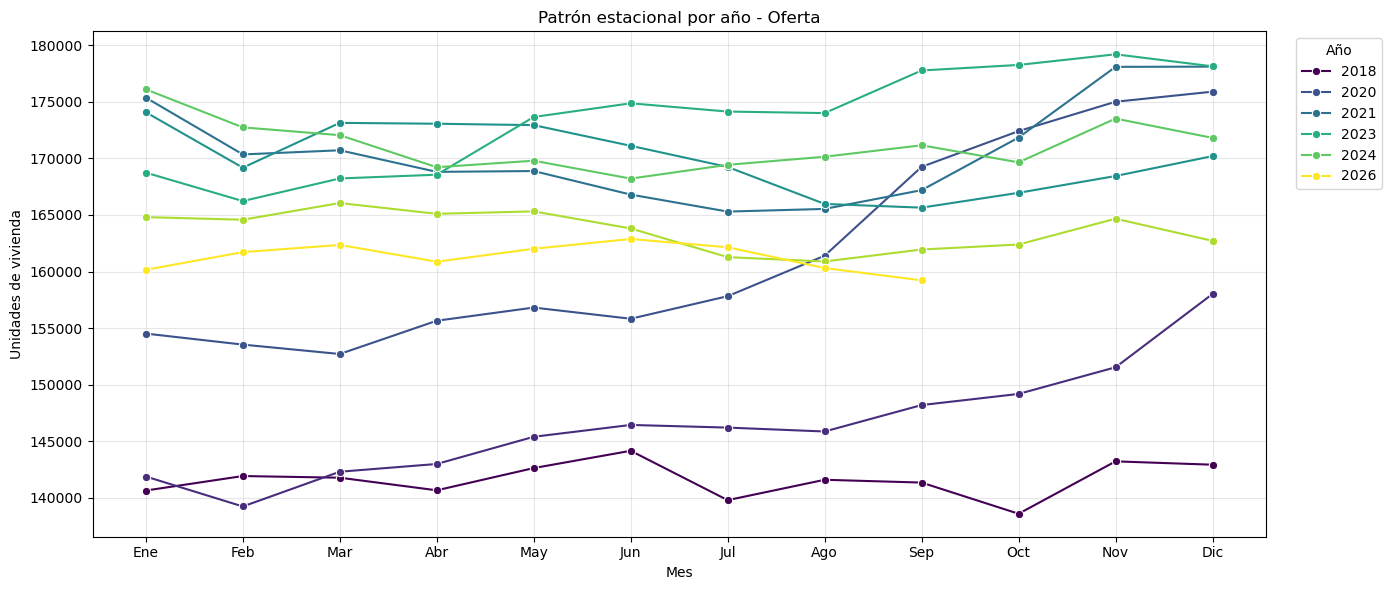

In [173]:
for variable in ['Lanzamientos', 'Iniciaciones', 'Ventas', 'Oferta']:

    plt.figure(figsize=(14, 6))

    sns.lineplot(
        data=df_coyuntura_nacional,
        x='Mes',
        y=variable,
        hue='Año',
        palette='viridis',
        marker='o'
    )

    plt.xticks(range(1, 13), meses)
    plt.title(f'Patrón estacional por año - {variable}')
    plt.xlabel('Mes')
    plt.ylabel('Unidades de vivienda')

    plt.legend(
        title='Año',
        bbox_to_anchor=(1.02, 1),
        loc='upper left'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()